<a id="top"></a>
# Polynomial Regression — Theory, Implementation & Diagnostics for *n*-Dimensional Data

**Goal of this notebook.** Fit and understand polynomial regression models for **any number of input features `m`** and **any polynomial degree `d`**, with one consistent pipeline for data generation, training, metric evaluation and visualisation (2-D, 3-D and *n*-D → 3-D).

| # | Section | What you get |
|---|---------|--------------|
| 1 | [Theory](#theory) | Notation, feature map, normal equation, bias–variance, metrics, diagnostics |
| 2 | [Setup & configuration](#setup) | Imports, global style, the `Config` object that drives everything |
| 3 | [Data: building `X` and `y` step by step](#data) | Generator for *m* features / degree *d*, term-count table, toy walkthrough |
| 4 | [Model](#model) | sklearn pipeline, `run_experiment`, from-scratch normal-equation check |
| 5 | [Unified metrics toolkit](#metrics-toolkit) | One function for every metric, auto-diagnostics, degree sweep |
| 6 | [Unified visualisation toolkit](#viz-toolkit) | One `visualize(exp, kind)` call for 2-D, 3-D and *n*-D plots |
| 7 | [Experiments A – D](#experiments) | 1, 2, 5 and 10 features — each plot followed by *Observation* and *Conclusion* |
| 8 | [All metric evaluations in one place](#metrics-all) | Consolidated table, automatic diagnostics, degree selection with CV |
| 9 | [Final conclusions & how to use on your own data](#conclusions) | Take-aways and a copy-paste recipe |



> **Reading guide.** Every plot in section 7 is followed by a block-quote with an **Observation** (what the figure shows) and a **Conclusion** (what we learn from it). Numbers quoted there belong to the default configuration (seed = 42); if you change the configuration, re-read the figure and use the automatic report of section 8, which adapts to your settings.


<a id="theory"></a>
---
# 1. Theory

This section builds the model from first principles: what the data look like, how a polynomial is turned into a *linear* problem, how the parameters are estimated, why a model can be too simple or too flexible, and how to judge a fit.

## 1.1 Problem statement and notation

We observe $n$ samples. Each sample has $m$ input **features** (also called predictors or independent variables) and one real-valued **target** (response, dependent variable).

$$
\mathcal D=\{(\mathbf x^{(i)},y^{(i)})\}_{i=1}^{n},\qquad
\mathbf x^{(i)}=\big(x^{(i)}_1,\dots,x^{(i)}_m\big)\in\mathbb R^{m},\quad y^{(i)}\in\mathbb R .
$$

The samples are stacked into the **feature matrix** $X$ and the **target vector** $\mathbf y$:

$$
X=\begin{bmatrix}
x^{(1)}_1 & x^{(1)}_2 & \cdots & x^{(1)}_m\\
x^{(2)}_1 & x^{(2)}_2 & \cdots & x^{(2)}_m\\
\vdots & \vdots & & \vdots\\
x^{(n)}_1 & x^{(n)}_2 & \cdots & x^{(n)}_m
\end{bmatrix}\in\mathbb R^{n\times m},
\qquad
\mathbf y=\begin{bmatrix}y^{(1)}\\ y^{(2)}\\ \vdots\\ y^{(n)}\end{bmatrix}\in\mathbb R^{n}.
$$

| Symbol | Meaning | Shape in code |
|---|---|---|
| $n$ | number of samples | `X.shape[0]` |
| $m$ | number of **original** features (the "dimension" of the input) | `X.shape[1]` |
| $d$ | polynomial degree | `degree` |
| $p$ | number of **polynomial terms** excluding the constant (new features after expansion) | `model[0].n_output_features_` |
| $\Phi$ | **design matrix** (expanded features) | `(n, p+1)` with a leading column of ones |
| $\boldsymbol\theta$ | parameter vector (intercept + one weight per term) | `(p+1,)` |

**Plot dimensionality.** With $m=1$ the data live in a **2-D** plot ($x$ vs. $y$); with $m=2$ in a **3-D** plot ($x_1,x_2,y$); for $m\ge3$ the full picture needs $m+1$ axes, so we use projections and slices (section 1.12).

## 1.2 Why polynomial regression?

Ordinary linear regression assumes $y\approx\theta_0+\theta_1x_1+\dots+\theta_mx_m$, i.e. a straight line (plane / hyper-plane). Real relationships are often **curved**. Any smooth function can be approximated locally by a polynomial (Taylor's theorem), and on a closed interval any continuous function can be approximated uniformly by polynomials (Weierstrass theorem). So a polynomial is a flexible, interpretable, low-tech way to capture curvature and **interactions** between features.

> **Key idea.** The model is *non-linear in the inputs* $x$ but **linear in the parameters** $\boldsymbol\theta$. We therefore create new features (powers and products of the originals) and run *ordinary linear regression* on them. Everything known about linear least squares — closed-form solution, statistics, diagnostics — carries over.

## 1.3 One feature ($m=1$): the polynomial feature map

For a scalar input $x$ and degree $d$, define the feature map

$$
\varphi(x)=\big(1,\;x,\;x^{2},\;\dots,\;x^{d}\big)^{\!\top},\qquad
\hat y=f_{\boldsymbol\theta}(x)=\theta_0+\theta_1x+\theta_2x^2+\dots+\theta_dx^d=\boldsymbol\theta^{\top}\varphi(x).
$$

Applying $\varphi$ to every sample gives the **Vandermonde design matrix**

$$
\Phi=\begin{bmatrix}
1 & x^{(1)} & (x^{(1)})^2 & \cdots & (x^{(1)})^d\\
1 & x^{(2)} & (x^{(2)})^2 & \cdots & (x^{(2)})^d\\
\vdots & & & & \vdots\\
1 & x^{(n)} & (x^{(n)})^2 & \cdots & (x^{(n)})^d
\end{bmatrix}\in\mathbb R^{n\times(d+1)},
\qquad \hat{\mathbf y}=\Phi\boldsymbol\theta .
$$

*Example* ($d=3$): `x = [0.5, -1.0, 2.0]` becomes the rows `[1, 0.5, 0.25, 0.125]`, `[1, -1, 1, -1]`, `[1, 2, 4, 8]`.

## 1.4 Several features ($m\ge2$): monomials and interaction terms

For $m$ features the feature map contains **all monomials of total degree $\le d$**:

$$
\varphi(\mathbf x)=\Big(\;x_1^{\alpha_1}x_2^{\alpha_2}\cdots x_m^{\alpha_m}\;\Big)_{\alpha\in\mathbb N^m,\;\alpha_1+\dots+\alpha_m\le d}.
$$

Terms with a single variable ($x_1^2$, $x_2^3$, …) bend the response along one axis; **mixed terms** ($x_1x_2$, $x_1^2x_2$, …) are *interactions*: the effect of one feature depends on the value of another.

*Example* $m=2,\ d=2$ (6 columns): $\;1,\;x_1,\;x_2,\;x_1^2,\;x_1x_2,\;x_2^2$.
*Example* $m=2,\ d=3$ (10 columns): the six above plus $x_1^3,\;x_1^2x_2,\;x_1x_2^2,\;x_2^3$.

**How many terms?** The number of monomials of total degree $\le d$ in $m$ variables (including the constant) is

$$
\boxed{\,P=\binom{m+d}{d}=\frac{(m+d)!}{m!\,d!}\,},\qquad p=P-1\ \text{(without the constant).}
$$

$P$ grows very quickly with both $m$ and $d$ (see the table in section 3) — this is the *curse of dimensionality* for polynomial models and the main practical limit on $d$ when $m$ is large.

The general model is

$$
\hat y=\boldsymbol\theta^{\top}\varphi(\mathbf x),\qquad \hat{\mathbf y}=\Phi\boldsymbol\theta,\qquad \Phi\in\mathbb R^{n\times P}.
$$

## 1.5 Data-generating process (how we simulate data)

To study the method we simulate data whose truth we know:

$$
y^{(i)}=f(\mathbf x^{(i)})+\varepsilon^{(i)},\qquad
f(\mathbf x)=\boldsymbol\theta^{\star\top}\varphi_{d^\star}(\mathbf x),\qquad
\varepsilon^{(i)}\overset{iid}{\sim}\mathcal N(0,\sigma^2).
$$

* $f$ is the **true polynomial** of degree $d^\star$ with coefficients $\boldsymbol\theta^\star$;
* $\varepsilon$ is **irreducible noise** — no model can predict it, so the best achievable RMSE is $\approx\sigma$ and the best achievable $R^2$ is $R^2_{\max}=1-\sigma^2/\operatorname{Var}(y)$ (the *noise ceiling*);
* $\mathbf x$ is drawn uniformly from a box $[a,b]^m$.

The model degree $d$ we *fit* can differ from $d^\star$; choosing $d<d^\star$ gives under-fitting, $d>d^\star$ allows over-fitting (section 1.8).

## 1.6 Parameter estimation (least squares)

**Loss.** Ordinary least squares minimises the sum of squared residuals

$$
J(\boldsymbol\theta)=\lVert\mathbf y-\Phi\boldsymbol\theta\rVert_2^2=\sum_{i=1}^{n}\big(y^{(i)}-\boldsymbol\theta^{\top}\varphi(\mathbf x^{(i)})\big)^2 .
$$

$J$ is a convex quadratic in $\boldsymbol\theta$, so it has a unique global minimum when $\Phi$ has full column rank.

**Gradient and normal equations.**

$$
\nabla_{\boldsymbol\theta}J=-2\,\Phi^{\top}(\mathbf y-\Phi\boldsymbol\theta)=\mathbf 0
\;\Longrightarrow\;
\boxed{\;\Phi^{\top}\Phi\,\hat{\boldsymbol\theta}=\Phi^{\top}\mathbf y\;}
\;\Longrightarrow\;
\hat{\boldsymbol\theta}=(\Phi^{\top}\Phi)^{-1}\Phi^{\top}\mathbf y=\Phi^{+}\mathbf y .
$$

$\Phi^{+}$ is the Moore–Penrose pseudo-inverse.

**Geometric view.** $\hat{\mathbf y}=\Phi\hat{\boldsymbol\theta}=H\mathbf y$ with the "hat matrix" $H=\Phi(\Phi^\top\Phi)^{-1}\Phi^\top$: the fitted values are the **orthogonal projection** of $\mathbf y$ onto the column space of $\Phi$, so the residual vector is orthogonal to every column of $\Phi$ ($\Phi^\top(\mathbf y-\hat{\mathbf y})=0$; in particular, residuals sum to zero when an intercept is included).

**Gradient descent alternative.** When $P$ is huge, iterate $\boldsymbol\theta\leftarrow\boldsymbol\theta+\dfrac{2\eta}{n}\Phi^{\top}(\mathbf y-\Phi\boldsymbol\theta)$ with learning rate $\eta$. Polynomial columns have wildly different scales ($x^5$ vs. $x$), so **standardise the features** first.

**Numerical practice.** Forming $(\Phi^\top\Phi)^{-1}$ squares the condition number, $\kappa(\Phi^\top\Phi)=\kappa(\Phi)^2$. Libraries therefore solve the least-squares problem with QR or SVD (`numpy.linalg.lstsq`, `sklearn.LinearRegression`). Cost is $O(nP^2)$ time. A large $\kappa(\Phi)$ — typical for high-degree monomials, which are strongly correlated — makes coefficients unstable.

**Ridge (L2) regularisation.** To tame large degrees add a penalty on the weights (not on the intercept):

$$
J_\alpha(\boldsymbol\theta)=\lVert\mathbf y-\Phi\boldsymbol\theta\rVert_2^2+\alpha\lVert\boldsymbol\theta_{1:}\rVert_2^2
\;\Rightarrow\;
\hat{\boldsymbol\theta}_\alpha=(\Phi^\top\Phi+\alpha I)^{-1}\Phi^\top\mathbf y .
$$

$\alpha=0$ gives OLS; larger $\alpha$ shrinks coefficients (more bias, less variance). The `Config.ridge_alpha` option in this notebook switches this on.

## 1.7 Statistical properties (why least squares is a good choice)

If $\varepsilon\sim\mathcal N(0,\sigma^2 I)$ and the model form is correct:

* the least-squares estimate **equals the maximum-likelihood estimate**;
* $\hat{\boldsymbol\theta}$ is **unbiased**, with covariance $\operatorname{Cov}(\hat{\boldsymbol\theta})=\sigma^2(\Phi^\top\Phi)^{-1}$ — nearly collinear monomials make $(\Phi^\top\Phi)^{-1}$ large, i.e. noisy coefficients;
* the unbiased noise estimate is $\hat\sigma^2=\dfrac{\lVert\mathbf y-\hat{\mathbf y}\rVert^2}{n-P}$ (we use it in the automatic report);
* by Gauss–Markov, OLS has the smallest variance among linear unbiased estimators.

**Assumptions to check** with the residual plots of section 1.10: (1) the mean function is polynomial of the chosen degree (*linearity in $\theta$*), (2) residuals have constant variance (*homoscedasticity*), (3) residuals are independent, (4) residuals are approximately normal (needed for confidence intervals, not for the point estimate).

## 1.8 Model complexity, bias–variance trade-off and choosing the degree

For a new point $\mathbf x_0$ the expected squared prediction error decomposes as

$$
\mathbb E\big[(y_0-\hat f(\mathbf x_0))^2\big]=\underbrace{\big(\mathbb E\hat f(\mathbf x_0)-f(\mathbf x_0)\big)^2}_{\text{bias}^2}+\underbrace{\operatorname{Var}\big(\hat f(\mathbf x_0)\big)}_{\text{variance}}+\underbrace{\sigma^2}_{\text{irreducible}} .
$$

| Degree $d$ vs. truth $d^\star$ | Regime | Typical symptoms |
|---|---|---|
| $d<d^\star$ | **Under-fitting** (high bias) | Train **and** test error high; residuals show a clear curve; fitted curve misses bends |
| $d=d^\star$ | **Good fit** | Train ≈ test error ≈ noise level $\sigma$; residuals look like random noise |
| $d>d^\star$ | **Over-fitting** (high variance) | Train error keeps dropping, test/CV error rises; wiggly curve, huge coefficients, extreme behaviour at the edges |

Adding a term can *never* increase the training error (the model class is nested), so **training error cannot be used to choose $d$**. Use a hold-out set or **$k$-fold cross-validation (CV)** and choose the smallest degree whose CV error is close to the minimum. Rule of thumb: keep $n\gtrsim10\,P$.

## 1.9 Evaluation metrics

With residuals $e_i=y_i-\hat y_i$, mean target $\bar y$, $n$ samples and $p$ polynomial terms (excluding the constant):

| Metric | Formula | Reading |
|---|---|---|
| **MSE** | $\frac1n\sum e_i^2$ | Average squared error; penalises large errors; units of $y^2$ |
| **RMSE** | $\sqrt{\mathrm{MSE}}$ | Typical error size in units of $y$; compare with $\sigma$ (noise floor) |
| **MAE** | $\frac1n\sum \lvert e_i\rvert$ | Average absolute error; more robust to outliers than RMSE |
| **MedAE** | $\operatorname{median}\lvert e_i\rvert$ | Median absolute error; very robust |
| **$R^2$** | $1-\dfrac{\sum e_i^2}{\sum (y_i-\bar y)^2}$ | Share of variance explained; 1 is perfect, 0 equals predicting $\bar y$, can be negative on test data |
| **Adjusted $R^2$** | $1-(1-R^2)\dfrac{n-1}{n-p-1}$ | $R^2$ penalised for the number of terms $p$; use it to compare different degrees |
| **Explained variance** | $1-\dfrac{\operatorname{Var}(e)}{\operatorname{Var}(y)}$ | Like $R^2$ but ignores a constant offset (bias) of the predictions |
| **Max error** | $\max\lvert e_i\rvert$ | Worst-case error |
| **MAPE** | $\frac{100}{n}\sum\left\lvert\dfrac{e_i}{y_i}\right\rvert$ | Relative error in %; **explodes when $y\approx0$** — unreliable for data that cross zero |
| **sMAPE** | $\frac{100}{n}\sum\dfrac{2\lvert e_i\rvert}{\lvert y_i\rvert+\lvert\hat y_i\rvert}$ | Symmetric variant; milder, still unreliable near zero |
| **Mean residual (bias)** | $\frac1n\sum e_i$ | ≈ 0 for OLS on training data; non-zero on test data signals systematic shift |

Always report metrics on **both train and test** sets. The ratio $\mathrm{RMSE}_{\text{test}}/\mathrm{RMSE}_{\text{train}}$ is the simplest over-fitting indicator (≈ 1 is healthy). The $R^2$ gap is less reliable on small test sets because $R^2$ also depends on how widely $y$ is spread in that particular split. For simulated data we also report an **oracle** row: the metrics of the *true* function $f$ on the same test targets — the best any model could do (its RMSE equals $\sigma$ and its $R^2$ is the noise ceiling).

> **Note on adjusted $R^2$.** The number of regressors is the number of *polynomial terms* $p=\binom{m+d}{d}-1$, **not** the degree $d$ or the number of original features $m$.

## 1.10 Residual diagnostics

The residual $e_i=y_i-\hat y_i$ is the model's footprint; a well-specified model leaves only noise.

| Plot | Healthy pattern | Warning sign → remedy |
|---|---|---|
| **Residuals vs. fitted $\hat y$** | Random cloud around 0, constant width | Curved band → degree too low (add terms); funnel → heteroscedastic noise (transform $y$, weighted LS) |
| **Residuals vs. each feature** | No trend in any feature | Trend in one feature → missing higher power / interaction involving it |
| **Histogram of residuals** | Bell shape centred at 0 | Skew or heavy tails → outliers, wrong error model |
| **Q–Q plot** | Points on the straight line | Curved ends → heavy tails; S-shape → skew |
| **Predicted vs. actual** | Points hug the 45° line, same scatter on train and test | Systematic bow → bias; much wider scatter on test → over-fitting |
| **Coefficients (true vs. estimated)** | Estimates track truth *(only checkable for simulated data)* | Large errors on high-order terms → collinearity / too little data |

## 1.11 Practical pitfalls

* **Extrapolation.** Polynomials leave the data range very quickly (a degree-$d$ term grows like $x^d$). Predictions outside the training box are unreliable — never extrapolate far.
* **Scaling.** Monomials of unscaled features have vastly different magnitudes; standardise features (or centre them) for gradient descent, ridge and numerical stability.
* **Collinearity.** $x$, $x^2$, $x^3$ are highly correlated on one-sided ranges; coefficient *values* become unstable even if predictions are fine. Compare predictions, not individual coefficients, in that case.
* **Dimension explosion.** $P=\binom{m+d}{d}$: with $m=10,d=3$ there are already 286 columns. Keep $d$ small, drop interactions, or use regularisation.
* **Hold-out discipline.** Do not tune $d$ on the test set — use CV on the training part.

## 1.12 Visualising models with many features

A model with $m$ inputs lives in $m+1$ dimensions; we can only draw 2 or 3 of them. This notebook uses the following honest views:

| Situation | View | How it is built |
|---|---|---|
| $m=1$ | **2-D curve** | scatter of $(x,y)$ + fitted curve + true curve |
| $m=2$ | **3-D surface** (+ contour) | surface $\hat y(x_1,x_2)$ over a grid, data as 3-D points |
| $m>2$ | **Slice surface** | choose the two most influential features $(x_i,x_j)$, **freeze all others at their mean** and draw the 3-D surface $\hat y(x_i,x_j)$; data are shown as *partial-residual points* $\;f(x_i,x_j,\bar{\mathbf x}_{\text{rest}})+(y-\hat y)$ so that the vertical scatter around the surface is exactly the model residual |
| $m>2$ | **Partial-dependence curves** | one 2-D curve per feature, others frozen at the mean |
| $m>2$ | **PCA projection to 3-D** | project $X$ onto its first 3 principal components and colour by actual and predicted $y$; shows whether prediction colours match actual colours across the whole cloud |
| any $m$ | **Dimension-agnostic diagnostics** | predicted vs. actual, residual plots, coefficient bars — these do not care about $m$ |

*Caveat.* A slice shows the model along a 2-D plane through the *mean point* only; other slices can look different when interactions are present. A PCA projection of independent features compresses poorly (all directions carry similar variance), so it is a sanity check, not a substitute for slices.

## 1.13 End-to-end algorithm

1. **Define** the problem: $m$ features, target $y$, polynomial degree $d$ (and, for simulation, true degree $d^\star$, noise $\sigma$).
2. **Build** $X\in\mathbb R^{n\times m}$ and $\mathbf y\in\mathbb R^n$.
3. **Split** into train and test sets (e.g. 80 / 20) with a fixed seed.
4. **Expand** features: $X\mapsto\Phi\in\mathbb R^{n\times P}$ (`PolynomialFeatures`).
5. **Fit** $\hat{\boldsymbol\theta}$ by least squares (optionally ridge).
6. **Predict** $\hat{\mathbf y}$ on train and test.
7. **Evaluate** all metrics on both sets; compare with the noise floor.
8. **Diagnose** with predicted-vs-actual and residual plots.
9. **Select** the degree by cross-validation; refit and report on the untouched test set.
10. **Visualise** the fitted function (curve / surface / slices) and interpret.

<a id="setup"></a>
---
# 2. Setup & configuration

All behaviour is controlled by the small `Config` object below. Every function in this notebook accepts a `Config` (or an `Experiment` built from one), so switching from 1 feature to 10 features or from degree 3 to degree 8 is a one-line change.

In [1]:
import math
import warnings
from dataclasses import dataclass, field, replace
from typing import Optional, Sequence

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from scipy import stats

from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (explained_variance_score, mean_absolute_error,
                             mean_squared_error, median_absolute_error, r2_score)
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42

# ---- plotting style (one palette for the whole notebook) ----
C_TRAIN, C_TEST, C_FIT, C_TRUE = "#4C72B0", "#DD8452", "#C44E52", "#2E8B57"
plt.rcParams.update({
    "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "legend.fontsize": 9,
})
# Works in JupyterLab / VS Code (mimetype) and classic notebooks (CDN fallback).
pio.renderers.default = "plotly_mimetype+notebook_connected"
pd.set_option("display.precision", 4)
print("Setup complete.")

Setup complete.


In [2]:
@dataclass
class Config:
    """Everything that defines one experiment."""
    name: str = "experiment"
    n_samples: int = 200
    n_features: int = 1                  # m : number of ORIGINAL input features
    true_degree: int = 3                 # d*: degree of the polynomial that generates the data
    model_degree: Optional[int] = None   # d : degree of the fitted model (None -> same as true_degree)
    x_range: tuple = (-3.0, 3.0)         # each feature ~ U(a, b)
    noise_std: float = 1.0                # sigma of the Gaussian noise
    coeffs: Optional[Sequence[float]] = None   # true coefficients (None -> random with decay)
    coeff_decay: float = 0.5             # random coeff of a term of order k is scaled by decay**(k-1)
    test_size: float = 0.2
    ridge_alpha: float = 0.0             # 0 -> ordinary least squares, >0 -> Ridge
    feature_names: Optional[Sequence[str]] = None
    seed: int = SEED

    def __post_init__(self):
        if self.model_degree is None:
            self.model_degree = self.true_degree
        if self.feature_names is None:
            self.feature_names = ["x"] if self.n_features == 1 else [f"x{k + 1}" for k in range(self.n_features)]
        self.feature_names = list(self.feature_names)

    @property
    def n_terms_model(self):
        """P = C(m + d, d) : number of columns of the design matrix (incl. constant)."""
        return math.comb(self.n_features + self.model_degree, self.model_degree)

<a id="data"></a>
---
# 3. Data: building `X` and `y` step by step

`generate_data(cfg)` implements section 1.5:

1. draw $X\in\mathbb R^{n\times m}$ uniformly in $[a,b]^m$;
2. expand it with the *true* degree $d^\star$ to get $\Phi^\star$;
3. choose true coefficients $\boldsymbol\theta^\star$ (given, or random with decay for higher-order terms so that all orders matter but none dominates);
4. compute the noise-free target $\mathbf y_{\text{true}}=\Phi^\star\boldsymbol\theta^\star$;
5. add Gaussian noise $\boldsymbol\varepsilon\sim\mathcal N(0,\sigma^2)$ to get the observed $\mathbf y$.

Real data can be used instead: `dataset_from_arrays(X, y)` wraps your own arrays (see section 9).

In [3]:
@dataclass
class Dataset:
    """Container for X, y and (when simulated) the ground truth."""
    X: np.ndarray                         # (n, m)
    y: np.ndarray                         # (n,)
    feature_names: list
    y_true: Optional[np.ndarray] = None   # noise-free target
    coeffs: Optional[np.ndarray] = None   # true coefficients theta*
    poly_true: Optional[PolynomialFeatures] = None

    @property
    def has_truth(self):
        return self.poly_true is not None

    def true_function(self, X_new):
        """Evaluate the noise-free true polynomial f(x) at arbitrary points."""
        return self.poly_true.transform(np.atleast_2d(X_new)) @ self.coeffs

    @property
    def true_term_names(self):
        return list(self.poly_true.get_feature_names_out(self.feature_names))


def generate_data(cfg: Config) -> Dataset:
    """Simulate  y = f(x) + eps  with f a polynomial of degree cfg.true_degree in cfg.n_features variables."""
    rng = np.random.default_rng(cfg.seed)
    lo, hi = cfg.x_range
    X = rng.uniform(lo, hi, size=(cfg.n_samples, cfg.n_features))            # step 1: X  (n, m)

    poly_true = PolynomialFeatures(degree=cfg.true_degree, include_bias=True)  # step 2: true basis
    Phi = poly_true.fit_transform(X)                                           #         (n, P*)

    if cfg.coeffs is None:                                                     # step 3: true coefficients
        order = poly_true.powers_.sum(axis=1)                                  # total degree of each term
        coeffs = rng.uniform(-1, 1, Phi.shape[1]) * cfg.coeff_decay ** np.maximum(order - 1, 0)
    else:
        coeffs = np.asarray(cfg.coeffs, dtype=float)
        if len(coeffs) != Phi.shape[1]:
            raise ValueError(f"coeffs must have {Phi.shape[1]} entries for m={cfg.n_features}, d={cfg.true_degree}; got {len(coeffs)}")

    y_true = Phi @ coeffs                                                      # step 4: noise-free target
    y = y_true + rng.normal(0.0, cfg.noise_std, cfg.n_samples)                 # step 5: add noise
    return Dataset(X, y, list(cfg.feature_names), y_true, coeffs, poly_true)


def dataset_from_arrays(X, y, feature_names=None) -> Dataset:
    """Wrap your own data (no ground truth available)."""
    X = np.asarray(X, float)
    X = X.reshape(-1, 1) if X.ndim == 1 else X
    names = list(feature_names) if feature_names is not None else (["x"] if X.shape[1] == 1 else [f"x{k+1}" for k in range(X.shape[1])])
    return Dataset(X, np.asarray(y, float), names)

### 3.1 How many terms does the design matrix have?

$P=\binom{m+d}{d}$ — rows are the number of features $m$, columns the degree $d$.

In [4]:
# Number of columns P = C(m+d, d) of the design matrix (incl. constant)
degrees = [1, 2, 3, 4, 5, 8]
features = [1, 2, 3, 5, 10, 20]
term_table = pd.DataFrame({f"d = {d}": [math.comb(m + d, d) for m in features] for d in degrees},
                          index=pd.Index(features, name="m features"))
term_table

,d = 1,d = 2,d = 3,d = 4,d = 5,d = 8
m features,,,,,,
1,2,3,4,5,6,9
2,3,6,10,15,21,45
3,4,10,20,35,56,165
5,6,21,56,126,252,1287
10,11,66,286,1001,3003,43758
20,21,231,1771,10626,53130,3108105


> **Observation** — The number of columns $P=\binom{m+d}{d}$ grows slowly with $d$ for a single feature ($m=1$: $P=d+1$, so 4 columns for a cubic) but explodes as soon as $m$ grows: $m=5,\,d=3$ gives 56 columns, $m=10,\,d=2$ gives 66, and $m=20,\,d=8$ would need more than 3 million.
>
> **Conclusion** — Degree and number of features cannot be chosen independently. As a rule of thumb keep $n\gtrsim10P$; for many features stay at $d=2$ or $3$, otherwise use regularisation or drop interaction terms. Experiments C and D below (21 and 66 columns) are therefore run at $d=2$.

### 3.2 Toy walk-through: from `X` and `y` to the design matrix `Φ`

Six samples, two features, degree 2 — small enough to see every number.

In [5]:
# ---- Toy walk-through: m = 2 features, degree 2, only 6 samples ----
toy_cfg = Config(name="toy", n_samples=6, n_features=2, true_degree=2, noise_std=0.3, x_range=(-2, 2))
toy = generate_data(toy_cfg)

print(f"X shape = {toy.X.shape}   (n samples, m features)")
print(f"y shape = {toy.y.shape}   (n samples,)\n")

# Step 1 – the feature matrix X and the observed target y
display(pd.DataFrame(np.c_[toy.X, toy.y], columns=toy.feature_names + ["y"]).round(3).rename_axis("sample"))

X shape = (6, 2)   (n samples, m features)
y shape = (6,)   (n samples,)



,x1,x2,y
sample,,,
0,1.096,-0.244,0.918
1,1.434,0.789,0.338
2,-1.623,1.902,-3.497
3,1.045,1.144,-0.175
4,-1.488,-0.198,-0.888
5,-0.517,1.707,-1.677


In [6]:
# Step 2 – the true polynomial: one coefficient per monomial
true_terms = ["1"] + [t for t in toy.true_term_names if t != "1"]
print("True model  f(x) = " + " ".join(f"{c:+.3f}·{t}" for c, t in zip(toy.coeffs, toy.true_term_names)))
print(f"Number of terms  P = C({toy_cfg.n_features}+{toy_cfg.true_degree}, {toy_cfg.true_degree}) = {len(toy.coeffs)}\n")

# Step 3 – design matrix Phi = [1, x1, x2, x1^2, x1*x2, x2^2]
Phi_toy = toy.poly_true.transform(toy.X)
display(pd.DataFrame(Phi_toy, columns=toy.true_term_names).round(3).rename_axis("sample"))

# Step 4 – y_true = Phi @ theta*, then y = y_true + noise
display(pd.DataFrame({"y_true = Phi·θ*": toy.y_true, "noise ε": toy.y - toy.y_true, "y = y_true + ε": toy.y}).round(3).rename_axis("sample"))

True model  f(x) = +0.288·1 +0.646·x1 -0.113·x2 -0.273·x1^2 +0.055·x1 x2 -0.436·x2^2
Number of terms  P = C(2+2, 2) = 6



,1,x1,x2,x1^2,x1 x2,x2^2
sample,,,,,,
0,1.0,1.096,-0.244,1.201,-0.268,0.060
1,1.0,1.434,0.789,2.057,1.132,0.623
2,1.0,-1.623,1.902,2.635,-3.088,3.619
3,1.0,1.045,1.144,1.091,1.195,1.309
4,1.0,-1.488,-0.198,2.213,0.295,0.039
5,1.0,-0.517,1.707,0.267,-0.882,2.914


,y_true = Phi·θ*,noise ε,y = y_true + ε
sample,,,
0,0.655,0.264,0.918
1,0.353,-0.015,0.338
2,-3.442,-0.055,-3.497
3,0.029,-0.204,-0.175
4,-1.255,0.367,-0.888
5,-1.631,-0.046,-1.677


> **Observation** — `X` has shape (6, 2) and `y` shape (6,). After the expansion the design matrix has shape (6, 6): the columns are $1,\,x_1,\,x_2,\,x_1^2,\,x_1x_2,\,x_2^2$. For sample 2, $x_1=-1.623$ and $x_2=1.902$ give $x_1^2=2.635$, $x_1x_2=-3.088$ and $x_2^2=3.619$. Multiplying each row of $\Phi$ by the six true coefficients gives `y_true`; the added noise lies between $-0.20$ and $+0.37$ (true $\sigma=0.3$), so `y` is `y_true` plus a small random shift.
>
> **Conclusion** — Polynomial regression only changes the *input* side: `X` $(n\times m)$ becomes `Φ` $(n\times P)$, while `y` $(n,)$ is untouched. After this step the problem is ordinary linear least squares.

<a id="model"></a>
---
# 4. Model

The model is the pipeline **`PolynomialFeatures(degree) → LinearRegression`** (or `Ridge` when `ridge_alpha > 0`). `run_experiment(cfg)` performs steps 2–6 of the algorithm in section 1.13 and returns one `Experiment` object that carries the data, the split, the fitted model and all predictions. Every metric and every plot in this notebook consumes that object.

In [7]:
def build_model(degree: int, ridge_alpha: float = 0.0):
    """x -> [x, x^2, ..., all monomials up to `degree`] -> (Ridge|Linear)Regression.
    The intercept is handled by the regressor, so include_bias=False."""
    reg = LinearRegression() if ridge_alpha == 0 else Ridge(alpha=ridge_alpha)
    return make_pipeline(PolynomialFeatures(degree=degree, include_bias=False), reg)


@dataclass
class Experiment:
    """Data + split + fitted model + predictions for one configuration."""
    cfg: Config
    data: Dataset
    model: object
    idx_train: np.ndarray
    idx_test: np.ndarray

    # ---- convenient views ----
    @property
    def X_train(self): return self.data.X[self.idx_train]
    @property
    def X_test(self): return self.data.X[self.idx_test]
    @property
    def y_train(self): return self.data.y[self.idx_train]
    @property
    def y_test(self): return self.data.y[self.idx_test]
    @property
    def y_train_pred(self): return self.model.predict(self.X_train)
    @property
    def y_test_pred(self): return self.model.predict(self.X_test)
    @property
    def res_train(self): return self.y_train - self.y_train_pred
    @property
    def res_test(self): return self.y_test - self.y_test_pred
    @property
    def is_train(self):
        mask = np.zeros(len(self.data.y), bool); mask[self.idx_train] = True
        return mask
    @property
    def n_terms(self):
        """p : number of polynomial terms WITHOUT the constant."""
        return self.model[0].n_output_features_

    def predict(self, X):
        return self.model.predict(X)


def run_experiment(cfg: Config, data: Optional[Dataset] = None) -> Experiment:
    """Steps 2-6 of the algorithm: data -> split -> expand -> fit -> (predict lazily)."""
    data = data if data is not None else generate_data(cfg)
    idx = np.arange(len(data.y))
    idx_tr, idx_te = train_test_split(idx, test_size=cfg.test_size, random_state=cfg.seed, shuffle=True)
    model = build_model(cfg.model_degree, cfg.ridge_alpha).fit(data.X[idx_tr], data.y[idx_tr])
    return Experiment(cfg, data, model, idx_tr, idx_te)


def coefficient_table(exp: Experiment) -> pd.DataFrame:
    """Estimated (and, if known, true) coefficient of every polynomial term."""
    poly, reg = exp.model[0], exp.model[-1]
    names = ["1"] + list(poly.get_feature_names_out(exp.cfg.feature_names))
    est = dict(zip(names, np.r_[reg.intercept_, reg.coef_]))
    if exp.data.has_truth:
        true = dict(zip(["1" if t == "1" else t for t in exp.data.true_term_names], exp.data.coeffs))
        all_names = names + [t for t in true if t not in est]
    else:
        true, all_names = {}, names
    tab = pd.DataFrame({"term": all_names,
                        "estimated": [est.get(t, 0.0) for t in all_names]})
    if true:
        tab["true"] = [true.get(t, 0.0) for t in all_names]
        tab["abs_error"] = (tab["estimated"] - tab["true"]).abs()
    return tab.set_index("term")

### 4.1 Verification: the closed-form normal equation reproduces sklearn

Before trusting the library pipeline we solve $\Phi^\top\Phi\,\theta=\Phi^\top y$ ourselves (section 1.6) and compare.

In [8]:
# ---- Verification: closed-form normal equation (from scratch) vs. sklearn ----
chk_cfg = Config(name="check", n_samples=120, n_features=2, true_degree=3, noise_std=0.5)
chk = run_experiment(chk_cfg)

Phi = PolynomialFeatures(chk_cfg.model_degree, include_bias=True).fit_transform(chk.X_train)   # (n_train, P)
y_tr = chk.y_train

theta_normal = np.linalg.solve(Phi.T @ Phi, Phi.T @ y_tr)            # (Φ'Φ)^-1 Φ'y  (normal equation)
theta_lstsq  = np.linalg.lstsq(Phi, y_tr, rcond=None)[0]             # SVD based, numerically preferred
theta_sk     = np.r_[chk.model[-1].intercept_, chk.model[-1].coef_]  # sklearn

print(f"Φ shape                      : {Phi.shape}  (n_train, P = C(2+3,3) = {math.comb(5, 3)})")
print(f"condition number κ(Φ)        : {np.linalg.cond(Phi):.1f}")
print(f"max |θ_normal − θ_sklearn|   : {np.max(np.abs(theta_normal - theta_sk)):.2e}")
print(f"max |θ_lstsq  − θ_sklearn|   : {np.max(np.abs(theta_lstsq  - theta_sk)):.2e}")
print(f"Φ'(y − Φθ) ≈ 0 (orthogonality): {np.max(np.abs(Phi.T @ (y_tr - Phi @ theta_normal))):.2e}")
print(f"sum of train residuals       : {np.sum(y_tr - Phi @ theta_normal):.2e}")

Φ shape                      : (96, 10)  (n_train, P = C(2+3,3) = 10)
condition number κ(Φ)        : 27.6
max |θ_normal − θ_sklearn|   : 8.88e-16
max |θ_lstsq  − θ_sklearn|   : 1.78e-15
Φ'(y − Φθ) ≈ 0 (orthogonality): 6.45e-13
sum of train residuals       : -7.33e-15


> **Observation** — The explicit normal equation, the SVD-based `lstsq` and sklearn agree to about $10^{-15}$. The residual vector is orthogonal to every column of $\Phi$ (largest inner product $\approx4\times10^{-13}$) and the residuals sum to zero ($\approx3\times10^{-14}$), exactly as the geometry of section 1.6 predicts. The condition number $\kappa(\Phi)\approx28$ is small.
>
> **Conclusion** — The library pipeline is a faithful implementation of the theory, so every number reported later can be trusted. For well-scaled data in $[-3,3]$ and moderate degrees the problem is well conditioned; $\kappa$ grows quickly with the degree (see the over-fitting discussion in section 8.3).

<a id="metrics-toolkit"></a>
---
# 5. Unified metrics toolkit

All metric computations live in this section:

* `regression_metrics` — every metric from section 1.9 in one dictionary;
* `evaluate(exp)` — train / test (/ oracle) table for one experiment;
* `compare(dict_of_experiments)` — one table for many experiments;
* `diagnose(exp)` — automatic textual diagnosis (over-fitting gap, noise estimate, residual structure, normality, heteroscedasticity, conditioning);
* `degree_sweep` — train / test / CV error versus polynomial degree.

In [9]:
METRIC_ORDER = ["n", "p", "MSE", "RMSE", "MAE", "MedAE", "R²", "Adj R²",
                "Explained Var", "Max |err|", "MAPE %", "sMAPE %", "Mean resid"]


def regression_metrics(y_true, y_pred, p: int) -> dict:
    """All metrics of section 1.9.  p = number of polynomial terms (without the constant)."""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    n, e = len(y_true), y_true - y_pred
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    adj = 1 - (1 - r2) * (n - 1) / (n - p - 1) if n - p - 1 > 0 else np.nan
    mape = np.mean(np.abs(e / y_true)) * 100 if np.min(np.abs(y_true)) > 1e-8 else np.nan
    smape = np.mean(2 * np.abs(e) / np.maximum(np.abs(y_true) + np.abs(y_pred), 1e-12)) * 100
    return {"n": n, "p": p, "MSE": mse, "RMSE": np.sqrt(mse),
            "MAE": mean_absolute_error(y_true, y_pred), "MedAE": median_absolute_error(y_true, y_pred),
            "R²": r2, "Adj R²": adj, "Explained Var": explained_variance_score(y_true, y_pred),
            "Max |err|": np.max(np.abs(e)), "MAPE %": mape, "sMAPE %": smape, "Mean resid": e.mean()}


def evaluate(exp: Experiment, oracle: bool = True) -> pd.DataFrame:
    """Metric table of one experiment: train, test and (if truth is known) the oracle f on the test targets."""
    rows = {"train": regression_metrics(exp.y_train, exp.y_train_pred, exp.n_terms),
            "test": regression_metrics(exp.y_test, exp.y_test_pred, exp.n_terms)}
    if oracle and exp.data.has_truth:
        p_true = len(exp.data.coeffs) - 1
        rows["oracle (true f, test)"] = regression_metrics(exp.y_test, exp.data.y_true[exp.idx_test], p_true)
    return pd.DataFrame(rows).T[METRIC_ORDER]


def compare(exps: dict) -> pd.DataFrame:
    """One table for many experiments: {label: Experiment} -> MultiIndex (experiment, split)."""
    return pd.concat({k: evaluate(v) for k, v in exps.items()}, names=["experiment", "split"])


def style_metrics(df: pd.DataFrame):
    fmt = {c: "{:.4f}" for c in df.columns}
    fmt.update({"n": "{:.0f}", "p": "{:.0f}", "MAPE %": "{:.1f}", "sMAPE %": "{:.1f}", "Max |err|": "{:.3f}", "Mean resid": "{:+.4f}"})
    return (df.style.format(fmt, na_rep="n/a")
              .background_gradient(subset=["R²", "Adj R²"], cmap="Greens", vmin=0, vmax=1)
              .background_gradient(subset=["RMSE"], cmap="Reds_r"))

In [10]:
def diagnose(exp: Experiment, verbose: bool = True) -> dict:
    """Automatic, configuration-independent diagnosis of one fitted model."""
    cfg, d = exp.cfg, exp.data
    mt, ms = regression_metrics(exp.y_train, exp.y_train_pred, exp.n_terms), regression_metrics(exp.y_test, exp.y_test_pred, exp.n_terms)
    n_tr, P = len(exp.y_train), exp.n_terms + 1
    out = {}

    out["R2_gap"] = mt["R²"] - ms["R²"]
    out["RMSE_ratio"] = ms["RMSE"] / mt["RMSE"]
    out["sigma_hat"] = np.sqrt(np.sum(exp.res_train ** 2) / (n_tr - P)) if n_tr > P else np.nan
    out["n_per_term"] = n_tr / P
    Phi = PolynomialFeatures(cfg.model_degree, include_bias=True).fit_transform(exp.X_train)
    out["cond"] = np.linalg.cond(Phi)

    # residual structure: mean residual inside quantile bins of the fitted value
    fitted_all, res_all = exp.model.predict(d.X), d.y - exp.model.predict(d.X)
    bins = np.array_split(np.argsort(fitted_all), 8)
    bin_means = np.array([res_all[b].mean() for b in bins])
    out["structure"] = np.max(np.abs(bin_means)) / np.std(res_all)
    out["spearman_abs_res_vs_fit"] = stats.spearmanr(np.abs(res_all), fitted_all)[0]
    out["shapiro_p"] = stats.shapiro(exp.res_train)[1] if 3 <= n_tr <= 5000 else np.nan
    out["skew"], out["kurt"] = stats.skew(res_all), stats.kurtosis(res_all)

    if verbose:
        print(f"━━ {cfg.name} ━━  (m={cfg.n_features}, model degree={cfg.model_degree}, P={P} terms, n_train={n_tr})")
        gap, ratio = out["R2_gap"], out["RMSE_ratio"]
        verdict = ("no sign of over-fitting" if ratio < 1.15 else
                   "mild generalisation gap" if ratio < 1.35 else "OVER-FITTING suspected")
        print(f"• Generalisation : RMSE train {mt['RMSE']:.3f} → test {ms['RMSE']:.3f} (ratio {ratio:.2f}) → {verdict}; "
              f"R² train {mt['R²']:.3f} vs test {ms['R²']:.3f} (gap {gap:+.3f})"
              + ("  [R² gap with RMSE ratio ≈ 1: the test split simply has a smaller spread of y]" if gap > 0.03 and ratio < 1.15 else ""))
        s = f"• Noise level    : σ̂ (from train residuals) = {out['sigma_hat']:.3f}"
        if d.has_truth:
            s += f"  vs true σ = {cfg.noise_std:.3f}  |  test RMSE = {ms['RMSE']:.3f}"
            ceiling = r2_score(exp.y_test, d.y_true[exp.idx_test])
            s += f"  |  noise-ceiling R² (test) = {ceiling:.3f}"
        print(s)
        print(f"• Residual shape : max |bin-mean residual| = {out['structure']:.2f}·std → "
              + ("no systematic curvature left" if out["structure"] < 0.5 else "STRUCTURE LEFT — degree may be too low"))
        print(f"• Heteroscedast. : Spearman(|res|, ŷ) = {out['spearman_abs_res_vs_fit']:+.2f} → "
              + ("roughly constant variance" if abs(out["spearman_abs_res_vs_fit"]) < 0.2 else "variance changes with ŷ"))
        print(f"• Normality      : Shapiro-Wilk p = {out['shapiro_p']:.3f}, skew = {out['skew']:+.2f}, excess kurtosis = {out['kurt']:+.2f} → "
              + ("residuals consistent with a normal distribution" if out["shapiro_p"] > 0.05 else "non-normal residuals"))
        print(f"• Conditioning   : κ(Φ) = {out['cond']:.1e}, samples per term = {out['n_per_term']:.1f} → "
              + ("well conditioned" if out["cond"] < 1e4 else "ill-conditioned (collinear monomials; interpret coefficients with care)"))
    return out

In [11]:
def degree_sweep(cfg: Config, degrees, cv: int = 5, data: Optional[Dataset] = None) -> pd.DataFrame:
    """Train / test / k-fold-CV error for every candidate degree (same data and same split)."""
    data = data if data is not None else generate_data(cfg)
    rows = []
    for dg in degrees:
        exp = run_experiment(replace(cfg, model_degree=dg), data)
        folds = KFold(cv, shuffle=True, random_state=cfg.seed)
        cv_rmse = -cross_val_score(build_model(dg, cfg.ridge_alpha), exp.X_train, exp.y_train,
                                   cv=folds, scoring="neg_root_mean_squared_error")
        mt = regression_metrics(exp.y_train, exp.y_train_pred, exp.n_terms)
        ms = regression_metrics(exp.y_test, exp.y_test_pred, exp.n_terms)
        rows.append({"degree": dg, "P terms": exp.n_terms + 1,
                     "train RMSE": mt["RMSE"], "CV RMSE": cv_rmse.mean(), "CV std": cv_rmse.std(), "test RMSE": ms["RMSE"],
                     "train R²": mt["R²"], "test R²": ms["R²"], "test Adj R²": ms["Adj R²"]})
    return pd.DataFrame(rows).set_index("degree")

<a id="viz-toolkit"></a>
---
# 6. Unified visualisation toolkit

A single entry point draws everything:

```python
visualize(exp, kind="fit")          # one plot
visualize(exp, kind="all")          # every plot that makes sense for this m
```

| `kind` | Works for | Content |
|---|---|---|
| `data` | any `m` | data (+ true function when known): 2-D scatter, 3-D scatter + true surface, or true-function slice |
| `fit` | any `m` | fitted model: 2-D curve (m = 1), 3-D surface (m = 2), slice surface (m > 2) |
| `contour` | m ≥ 2 | filled contour of the fitted surface (slice for m > 2) |
| `pdp` | m ≥ 2 | partial-dependence curve per feature |
| `projection` | m ≥ 3 | PCA → 3-D scatter coloured by actual and predicted y |
| `pred_vs_actual` | any `m` | predicted vs. actual, train and test |
| `residuals` | any `m` | residuals vs. fitted, histogram, Q–Q |
| `residuals_vs_features` | m ≥ 2 | residuals against every feature |
| `coefficients` | any `m` | true vs. estimated coefficients |

Extra options, e.g. `visualize(exp, "fit", pair=(0, 3))` chooses which two features form the 3-D slice for `m > 2`.

In [12]:
# ---------------------------------------------------------------- helpers ----
def _pair_grid(X, i, j, n_grid=45):
    """Grid over features i and j; all other features frozen at their mean."""
    gi, gj = np.linspace(X[:, i].min(), X[:, i].max(), n_grid), np.linspace(X[:, j].min(), X[:, j].max(), n_grid)
    Gi, Gj = np.meshgrid(gi, gj)
    base = np.tile(X.mean(axis=0), (Gi.size, 1))
    base[:, i], base[:, j] = Gi.ravel(), Gj.ravel()
    return gi, gj, Gi.shape, base


def _auto_pair(X, f):
    """The two features whose individual effect (range of f with others at the mean) is largest."""
    effect = []
    for k in range(X.shape[1]):
        g = np.tile(X.mean(axis=0), (60, 1)); g[:, k] = np.linspace(X[:, k].min(), X[:, k].max(), 60)
        effect.append(np.ptp(f(g)))
    return tuple(sorted(np.argsort(effect)[::-1][:2]))


def _slice_points(X, y, f, i, j):
    """Partial-residual points: f(x_i, x_j, rest at mean) + (y - f(x)).  For m = 2 this is exactly y."""
    pts = np.tile(X.mean(axis=0), (len(X), 1)); pts[:, i], pts[:, j] = X[:, i], X[:, j]
    return f(pts) + (y - f(X))


def _title_slice(exp, i, j, what):
    m, nm = exp.cfg.n_features, exp.cfg.feature_names
    base = f"{what} — degree {exp.cfg.model_degree}"
    return base if m == 2 else f"{base}<br><sup>slice over {nm[i]} and {nm[j]}; other {m-2} feature(s) fixed at their mean; points = partial residuals</sup>"

In [13]:
# ------------------------------------------------------------ 2-D (m = 1) ----
def _plot_curve2d(exp, with_model=True):
    d, cfg = exp.data, exp.cfg
    fig, ax = plt.subplots(figsize=(9.5, 5.2))
    xx = np.linspace(d.X.min(), d.X.max(), 500).reshape(-1, 1)
    ax.scatter(exp.X_train, exp.y_train, s=28, color=C_TRAIN, alpha=0.65, edgecolor="k", linewidth=0.3, label="train data")
    ax.scatter(exp.X_test, exp.y_test, s=46, color=C_TEST, marker="^", alpha=0.9, edgecolor="k", linewidth=0.3, label="test data")
    if d.has_truth:
        ax.plot(xx, d.true_function(xx), color=C_TRUE, ls="--", lw=2, label="true polynomial f(x)")
    if with_model:
        yhat = exp.model.predict(xx)
        sigma = np.sqrt(np.mean(exp.res_train ** 2))
        ax.plot(xx, yhat, color=C_FIT, lw=2.5, label=f"fitted model (degree {cfg.model_degree})")
        ax.fill_between(xx.ravel(), yhat - 2 * sigma, yhat + 2 * sigma, color=C_FIT, alpha=0.10, label="ŷ ± 2·RMSE(train)")
    ax.set_xlabel(cfg.feature_names[0]); ax.set_ylabel("y")
    ax.set_title(f"{'Fitted model' if with_model else 'Data'} — {cfg.name}")
    ax.legend(loc="best"); plt.tight_layout(); plt.show()

In [14]:
# ------------------------------------------------------------ 3-D (m >= 2) ----
def plot_surface3d(exp, mode="fit", pair=None, n_grid=45, show_true=True):
    """mode='fit' : fitted surface (+ faint true surface) ;  mode='data' : true surface only."""
    d, cfg = exp.data, exp.cfg
    X, y = d.X, d.y
    f_ref = exp.model.predict if mode == "fit" else d.true_function
    i, j = pair if pair is not None else _auto_pair(X, f_ref)
    gi, gj, shape, base = _pair_grid(X, i, j, n_grid)
    Z = f_ref(base).reshape(shape)
    zpts = _slice_points(X, y, f_ref, i, j)
    tr = exp.is_train
    fig = go.Figure()
    fig.add_trace(go.Surface(x=gi, y=gj, z=Z, colorscale="Viridis", opacity=0.85, showscale=False,
                             name="fitted ŷ" if mode == "fit" else "true f(x)", showlegend=True))
    if mode == "fit" and show_true and d.has_truth:
        fig.add_trace(go.Surface(x=gi, y=gj, z=d.true_function(base).reshape(shape), opacity=0.30, showscale=False,
                                 colorscale=[[0, C_TRUE], [1, C_TRUE]], name="true f(x)", showlegend=True))
    fig.add_trace(go.Scatter3d(x=X[tr, i], y=X[tr, j], z=zpts[tr], mode="markers", name="train",
                               marker=dict(size=2.6, color=C_TRAIN, opacity=0.75)))
    fig.add_trace(go.Scatter3d(x=X[~tr, i], y=X[~tr, j], z=zpts[~tr], mode="markers", name="test",
                               marker=dict(size=3.4, color=C_TEST, symbol="diamond", opacity=0.95)))
    fig.update_layout(title=_title_slice(exp, i, j, "Fitted surface" if mode == "fit" else "True function and data"),
                      scene=dict(xaxis_title=cfg.feature_names[i], yaxis_title=cfg.feature_names[j], zaxis_title="y",
                                 camera=dict(eye=dict(x=1.6, y=-1.6, z=0.9))),
                      height=650, margin=dict(l=0, r=0, t=70, b=0), legend=dict(orientation="h", y=0.02))
    fig.show()


def plot_contour(exp, pair=None, n_grid=70):
    d, cfg = exp.data, exp.cfg
    i, j = pair if pair is not None else _auto_pair(d.X, exp.model.predict)
    gi, gj, shape, base = _pair_grid(d.X, i, j, n_grid)
    Z = exp.model.predict(base).reshape(shape)
    tr = exp.is_train
    fig = go.Figure(go.Contour(x=gi, y=gj, z=Z, colorscale="Viridis", colorbar=dict(title="ŷ", x=1.02),
                               contours=dict(showlines=True)))
    fig.add_trace(go.Scatter(x=d.X[tr, i], y=d.X[tr, j], mode="markers", name="train",
                             marker=dict(size=6, color=d.y[tr], colorscale="Viridis", cmin=Z.min(), cmax=Z.max(),
                                         line=dict(color="black", width=0.7))))
    fig.add_trace(go.Scatter(x=d.X[~tr, i], y=d.X[~tr, j], mode="markers", name="test",
                             marker=dict(size=9, symbol="diamond", color=d.y[~tr], colorscale="Viridis", cmin=Z.min(), cmax=Z.max(),
                                         line=dict(color="black", width=1.2))))
    sub = "" if cfg.n_features == 2 else f"<br><sup>other {cfg.n_features-2} feature(s) fixed at their mean; point colour = actual y</sup>"
    fig.update_layout(title=f"Contour of the fitted surface — degree {cfg.model_degree}{sub}",
                      xaxis_title=cfg.feature_names[i], yaxis_title=cfg.feature_names[j], height=600,
                      legend=dict(orientation="h", y=-0.16, x=0.0), margin=dict(b=80))
    fig.show()

In [15]:
# ------------------------------------------------------------ n-D -> 3-D ----
def plot_projection(exp):
    """PCA of X onto 3 components; left coloured by actual y, right by predicted y (same colour scale)."""
    d = exp.data
    if d.X.shape[1] < 3:
        print("projection needs m >= 3 features"); return
    pca = PCA(n_components=3, random_state=0).fit(d.X)
    Z, evr = pca.transform(d.X), pca.explained_variance_ratio_
    yhat = exp.model.predict(d.X)
    lo, hi = min(d.y.min(), yhat.min()), max(d.y.max(), yhat.max())
    fig = make_subplots(rows=1, cols=2, specs=[[{"type": "scene"}, {"type": "scene"}]],
                        subplot_titles=("Actual y", "Predicted ŷ"))
    for col, vals in enumerate([d.y, yhat], start=1):
        fig.add_trace(go.Scatter3d(x=Z[:, 0], y=Z[:, 1], z=Z[:, 2], mode="markers", showlegend=False,
                                   marker=dict(size=3.3, color=vals, colorscale="Viridis", cmin=lo, cmax=hi, opacity=0.85,
                                               showscale=(col == 2), colorbar=dict(title="y", len=0.7))), row=1, col=col)
    fig.update_scenes(xaxis_title=f"PC1 ({evr[0]*100:.0f}%)", yaxis_title=f"PC2 ({evr[1]*100:.0f}%)", zaxis_title=f"PC3 ({evr[2]*100:.0f}%)")
    fig.update_scenes(aspectmode="cube", camera=dict(eye=dict(x=1.7, y=1.7, z=1.0)))
    fig.update_layout(height=560, margin=dict(l=0, r=0, t=80, b=0),
                      title=f"{d.X.shape[1]}-D inputs projected to 3-D (PCA) — the 3 PCs keep {evr.sum()*100:.0f}% of the input variance")
    fig.show()


def plot_pdp(exp, n_grid=120, ncols=3):
    """Partial dependence: one curve per feature, the other features fixed at their mean."""
    d, cfg = exp.data, exp.cfg
    X, y, m = d.X, d.y, d.X.shape[1]
    nrows = math.ceil(m / ncols)
    fig, axes = plt.subplots(nrows, min(m, ncols), figsize=(4.6 * min(m, ncols), 3.5 * nrows), squeeze=False, sharey=True)
    yhat = exp.model.predict(X)
    for k, ax in enumerate(axes.ravel()):
        if k >= m: ax.axis("off"); continue
        g = np.tile(X.mean(axis=0), (n_grid, 1)); g[:, k] = np.linspace(X[:, k].min(), X[:, k].max(), n_grid)
        pts = np.tile(X.mean(axis=0), (len(X), 1)); pts[:, k] = X[:, k]
        ax.scatter(X[:, k], exp.model.predict(pts) + (y - yhat), s=7, alpha=0.3, color=C_TRAIN, label="partial residuals")
        if d.has_truth:
            ax.plot(g[:, k], d.true_function(g), color=C_TRUE, ls="--", lw=2, label="true f")
        ax.plot(g[:, k], exp.model.predict(g), color=C_FIT, lw=2.2, label="fitted")
        ax.set_xlabel(cfg.feature_names[k]); ax.set_title(cfg.feature_names[k])
        if k % ncols == 0: ax.set_ylabel("y (others at mean)")
    axes.ravel()[0].legend(loc="best")
    fig.suptitle(f"Partial-dependence curves — {cfg.name}", fontsize=13, fontweight="bold", y=1.02)
    plt.tight_layout(); plt.show()

In [16]:
# ------------------------------------------------------ dimension-agnostic ----
def plot_pred_vs_actual(exp):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 5), sharex=True, sharey=True)
    lo = min(exp.data.y.min(), exp.model.predict(exp.data.X).min()); hi = max(exp.data.y.max(), exp.model.predict(exp.data.X).max())
    pad = 0.04 * (hi - lo); lims = [lo - pad, hi + pad]
    for ax, (yt, yp, name, col, mk) in zip(axes, [(exp.y_train, exp.y_train_pred, "Train", C_TRAIN, "o"),
                                                  (exp.y_test, exp.y_test_pred, "Test", C_TEST, "^")]):
        ax.scatter(yt, yp, s=26, alpha=0.7, color=col, marker=mk, edgecolor="k", linewidth=0.3)
        ax.plot(lims, lims, "k--", lw=1.2, label="ideal ŷ = y")
        ax.set_xlim(lims); ax.set_ylim(lims); ax.set_aspect("equal", adjustable="box")
        r2, rmse = r2_score(yt, yp), np.sqrt(mean_squared_error(yt, yp))
        ax.set_title(f"{name}: R² = {r2:.3f}, RMSE = {rmse:.3f}"); ax.set_xlabel("actual y"); ax.set_ylabel("predicted ŷ"); ax.legend(loc="upper left")
    fig.suptitle(f"Predicted vs. actual — {exp.cfg.name}", fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()


def plot_residuals(exp, n_bins=10):
    """Residual vs fitted (with binned trend), histogram + normal pdf, Q-Q plot."""
    yhat_all = exp.model.predict(exp.data.X); res_all = exp.data.y - yhat_all; tr = exp.is_train
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
    ax = axes[0]
    ax.scatter(yhat_all[tr], res_all[tr], s=18, alpha=0.55, color=C_TRAIN, label="train")
    ax.scatter(yhat_all[~tr], res_all[~tr], s=34, alpha=0.9, color=C_TEST, marker="^", label="test")
    order = np.argsort(yhat_all); chunks = np.array_split(order, n_bins)
    ax.plot([yhat_all[c].mean() for c in chunks], [res_all[c].mean() for c in chunks], color=C_FIT, lw=2.2, marker="o", ms=4, label="binned mean")
    ax.axhline(0, color="k", ls="--", lw=1); ax.set_xlabel("fitted ŷ"); ax.set_ylabel("residual y − ŷ"); ax.set_title("Residuals vs fitted"); ax.legend()
    ax = axes[1]
    ax.hist(res_all[tr], bins=22, density=True, alpha=0.6, color=C_TRAIN, edgecolor="k", label="train")
    ax.hist(res_all[~tr], bins=12, density=True, alpha=0.6, color=C_TEST, edgecolor="k", label="test")
    xs = np.linspace(res_all.min(), res_all.max(), 300)
    ax.plot(xs, stats.norm.pdf(xs, res_all.mean(), res_all.std()), color=C_FIT, lw=2, label="N(μ, σ) fit")
    ax.set_xlabel("residual"); ax.set_ylabel("density"); ax.set_title("Residual distribution"); ax.legend()
    ax = axes[2]
    (osm, osr), (slope, icpt, r) = stats.probplot(res_all, dist="norm")
    ax.scatter(osm, osr, s=18, alpha=0.7, color=C_TEST, edgecolor="k", linewidth=0.3)
    ax.plot(osm, slope * osm + icpt, color=C_FIT, lw=2, label=f"reference line (r = {r:.3f})")
    ax.set_xlabel("theoretical quantiles"); ax.set_ylabel("ordered residuals"); ax.set_title("Q–Q plot"); ax.legend()
    fig.suptitle(f"Residual diagnostics — {exp.cfg.name}", fontsize=13, fontweight="bold", y=1.03)
    plt.tight_layout(); plt.show()


def plot_residuals_vs_features(exp, ncols=5):
    d, cfg = exp.data, exp.cfg
    res = d.y - exp.model.predict(d.X); tr = exp.is_train; m = d.X.shape[1]
    ncols = min(m, ncols); nrows = math.ceil(m / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.3 * ncols, 2.9 * nrows), squeeze=False, sharey=True)
    for k, ax in enumerate(axes.ravel()):
        if k >= m: ax.axis("off"); continue
        ax.scatter(d.X[tr, k], res[tr], s=7, alpha=0.4, color=C_TRAIN); ax.scatter(d.X[~tr, k], res[~tr], s=14, alpha=0.8, color=C_TEST, marker="^")
        order = np.argsort(d.X[:, k]); chunks = np.array_split(order, 8)
        ax.plot([d.X[c, k].mean() for c in chunks], [res[c].mean() for c in chunks], color=C_FIT, lw=1.8)
        ax.axhline(0, color="k", ls="--", lw=0.8); ax.set_title(cfg.feature_names[k], fontsize=10)
        if k % ncols == 0: ax.set_ylabel("residual")
    fig.suptitle(f"Residuals vs each feature — {cfg.name}", fontsize=13, fontweight="bold", y=1.02)
    plt.tight_layout(); plt.show()


def plot_coefficients(exp, top_k=24):
    tab = coefficient_table(exp)
    key = tab["true"].abs() if "true" in tab else tab["estimated"].abs()
    tab = tab.loc[key.sort_values(ascending=False).index[:top_k]].iloc[::-1]
    labels = [t.replace(" ", "·") for t in tab.index]
    fig, ax = plt.subplots(figsize=(8.5, 0.34 * len(tab) + 1.8))
    yy = np.arange(len(tab)); h = 0.38
    if "true" in tab:
        ax.barh(yy + h / 2, tab["true"], height=h, color=C_TRUE, alpha=0.85, label="true coefficient")
    ax.barh(yy - h / 2 if "true" in tab else yy, tab["estimated"], height=h, color=C_FIT, alpha=0.85, label="estimated coefficient")
    ax.set_yticks(yy); ax.set_yticklabels(labels); ax.axvline(0, color="k", lw=0.8)
    ax.set_xlabel("coefficient value")
    err = f"  |  max error (shown terms) = {tab['abs_error'].max():.3f}" if "abs_error" in tab else ""
    ax.set_title(f"Coefficients ({len(tab)} of {len(coefficient_table(exp))} terms, ranked by size){err}", fontsize=11)
    ax.legend(loc="best"); plt.tight_layout(); plt.show()

In [17]:
# -------------------------------------------------- degree studies (any m) ----
def plot_degree_comparison(cfg: Config, degrees=(1, 3, 12), data: Optional[Dataset] = None):
    """m = 1 only: same data and split, fitted with different degrees side by side."""
    assert cfg.n_features == 1, "degree comparison curves are drawn for m = 1"
    data = data if data is not None else generate_data(cfg)
    fig, axes = plt.subplots(1, len(degrees), figsize=(5.4 * len(degrees), 4.6), sharey=True)
    for ax, dg in zip(np.atleast_1d(axes), degrees):
        e = run_experiment(replace(cfg, model_degree=dg), data)
        xx = np.linspace(data.X.min(), data.X.max(), 500).reshape(-1, 1)
        ax.scatter(e.X_train, e.y_train, s=18, color=C_TRAIN, alpha=0.55, label="train")
        ax.scatter(e.X_test, e.y_test, s=30, color=C_TEST, marker="^", alpha=0.9, label="test")
        if data.has_truth: ax.plot(xx, data.true_function(xx), color=C_TRUE, ls="--", lw=1.8, label="true f")
        ax.plot(xx, e.model.predict(xx), color=C_FIT, lw=2.4, label="fit")
        mt, ms = regression_metrics(e.y_train, e.y_train_pred, e.n_terms), regression_metrics(e.y_test, e.y_test_pred, e.n_terms)
        ax.set_ylim(data.y.min() - 2, data.y.max() + 2)
        ax.set_title(f"degree {dg}  (P = {e.n_terms + 1})\ntrain RMSE {mt['RMSE']:.2f} | test RMSE {ms['RMSE']:.2f}", fontsize=11)
        ax.set_xlabel(cfg.feature_names[0])
    np.atleast_1d(axes)[0].set_ylabel("y"); np.atleast_1d(axes)[0].legend(loc="upper left")
    fig.suptitle("Effect of the polynomial degree: under-fit → good fit → over-fit", fontsize=13, fontweight="bold", y=1.03)
    plt.tight_layout(); plt.show()


def plot_degree_sweep(sweep: pd.DataFrame, cfg: Config):
    best = sweep["CV RMSE"].idxmin()
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
    ax = axes[0]
    ax.plot(sweep.index, sweep["train RMSE"], "o-", color=C_TRAIN, label="train RMSE")
    ax.errorbar(sweep.index, sweep["CV RMSE"], yerr=sweep["CV std"], fmt="s-", color="purple", capsize=3, label="5-fold CV RMSE (train part)")
    ax.plot(sweep.index, sweep["test RMSE"], "^-", color=C_TEST, label="test RMSE")
    ax.axhline(cfg.noise_std, color=C_TRUE, ls=":", lw=2, label=f"noise floor σ = {cfg.noise_std:g}")
    ax.axvline(cfg.true_degree, color=C_TRUE, ls="--", alpha=0.6, label=f"true degree {cfg.true_degree}")
    ax.axvline(best, color="purple", ls="--", alpha=0.6, label=f"CV-best degree {best}")
    ax.set_yscale("log"); ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}")); ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.set_xlabel("polynomial degree"); ax.set_ylabel("RMSE (log scale)"); ax.set_title("Error vs. degree"); ax.legend(fontsize=8)
    ax = axes[1]
    ax.plot(sweep.index, sweep["train R²"], "o-", color=C_TRAIN, label="train R²")
    ax.plot(sweep.index, sweep["test R²"], "^-", color=C_TEST, label="test R²")
    ax.plot(sweep.index, sweep["test Adj R²"], "d--", color="gray", label="test adjusted R²")
    ax.axvline(cfg.true_degree, color=C_TRUE, ls="--", alpha=0.6)
    lo = max(min(sweep["test R²"].min(), sweep["train R²"].min()) - 0.05, -1)
    ax.set_ylim(lo, 1.02); ax.set_xlabel("polynomial degree"); ax.set_ylabel("R²"); ax.set_title("R² vs. degree"); ax.legend(fontsize=8)
    fig.suptitle(f"Degree selection — {cfg.name}", fontsize=13, fontweight="bold", y=1.03)
    plt.tight_layout(); plt.show()

In [18]:
def visualize(exp: Experiment, kind: str = "all", **kw):
    """One entry point for every plot.  kind in {data, fit, contour, pdp, projection, pred_vs_actual,
    residuals, residuals_vs_features, coefficients, all}.  Extra kwargs go to the underlying function."""
    m = exp.cfg.n_features

    def _data(e, **k):
        if m == 1: return _plot_curve2d(e, with_model=False)
        if not e.data.has_truth:
            return plot_projection(e) if m >= 3 else plot_surface3d(e, "fit", **k)   # no truth: show the model instead
        return plot_surface3d(e, "data", **k)

    def _fit(e, **k):
        return _plot_curve2d(e, with_model=True) if m == 1 else plot_surface3d(e, "fit", **k)

    registry = {"data": _data, "fit": _fit, "contour": plot_contour, "pdp": plot_pdp, "projection": plot_projection,
                "pred_vs_actual": plot_pred_vs_actual, "residuals": plot_residuals,
                "residuals_vs_features": plot_residuals_vs_features, "coefficients": plot_coefficients}
    applicable = (["data", "fit"] + (["contour", "pdp"] if m >= 2 else []) + (["projection"] if m >= 3 else [])
                  + ["pred_vs_actual", "residuals"] + (["residuals_vs_features"] if m >= 2 else []) + ["coefficients"])
    kinds = applicable if kind == "all" else ([kind] if isinstance(kind, str) else list(kind))
    for k in kinds:
        if k not in registry: raise ValueError(f"unknown kind '{k}'. Choose from {list(registry)}")
        if k not in applicable: print(f"[skip] '{k}' does not apply to m = {m} features"); continue
        registry[k](exp, **kw) if k in ("data", "fit", "contour") else registry[k](exp)

<a id="experiments"></a>
---
# 7. Experiments A – D

Four experiments use exactly the same code and differ only in `Config`:

| Exp. | Features $m$ | True degree $d^\star$ | Model degree $d$ | Terms $P$ | Plot type |
|---|---|---|---|---|---|
| **A** | 1 | 3 | 3 | 4 | 2-D |
| **B** | 2 | 3 | 3 | 10 | 3-D surface |
| **C** | 5 | 2 | 2 | 21 | slice, partial dependence, 3-D PCA |
| **D** | 10 | 2 | 2 | 66 | high-dimensional stress test |

After every plot you find an **Observation** and a **Conclusion**.

## 7.A  One feature, degree 3 — 2-D plots

This reproduces and extends your original setup: $y=0.5-1.5x+0.8x^2+0.3x^3+\varepsilon$, $\sigma=1.5$, 200 samples.

In [19]:
# ---------------- Experiment A : 1 feature, degree 3  (2-D plots) ----------------
cfg_A = Config(name="A: m=1, d=3", n_samples=200, n_features=1, true_degree=3, noise_std=1.5,
               coeffs=[0.5, -1.5, 0.8, 0.3])            # θ* = [a0, a1, a2, a3]  (your original setup)
exp_A = run_experiment(cfg_A)

print(f"X_train {exp_A.X_train.shape} | y_train {exp_A.y_train.shape} | X_test {exp_A.X_test.shape} | y_test {exp_A.y_test.shape}")
print(f"True model   : y = 0.5 − 1.5x + 0.8x² + 0.3x³ + ε,  ε ~ N(0, {cfg_A.noise_std}²)")
display(coefficient_table(exp_A).round(4))

X_train (160, 1) | y_train (160,) | X_test (40, 1) | y_test (40,)
True model   : y = 0.5 − 1.5x + 0.8x² + 0.3x³ + ε,  ε ~ N(0, 1.5²)


,estimated,true,abs_error
term,,,
1,0.4396,0.5,0.0604
x,-1.2895,-1.5,0.2105
x^2,0.7951,0.8,0.0049
x^3,0.2921,0.3,0.0079


> **Observation** — 160 training and 40 test samples. The estimated coefficients are $\hat\theta=(0.440,\,-1.290,\,0.795,\,0.292)$ against the true $(0.5,\,-1.5,\,0.8,\,0.3)$. The quadratic and cubic terms are recovered within 0.01; the largest error (0.21) is on the linear term.
>
> **Conclusion** — Ordinary least squares recovers the generating polynomial even with noise $\sigma=1.5$ (which is large compared with the curve). The linear term is the least certain one: with the true $\sigma$ its standard error is $\approx0.18$, and $x$ and $x^3$ are strongly correlated on this symmetric range ($r\approx0.92$), so an error of 0.21 is only about 1.2 standard errors.

### A.1 Data and the true polynomial

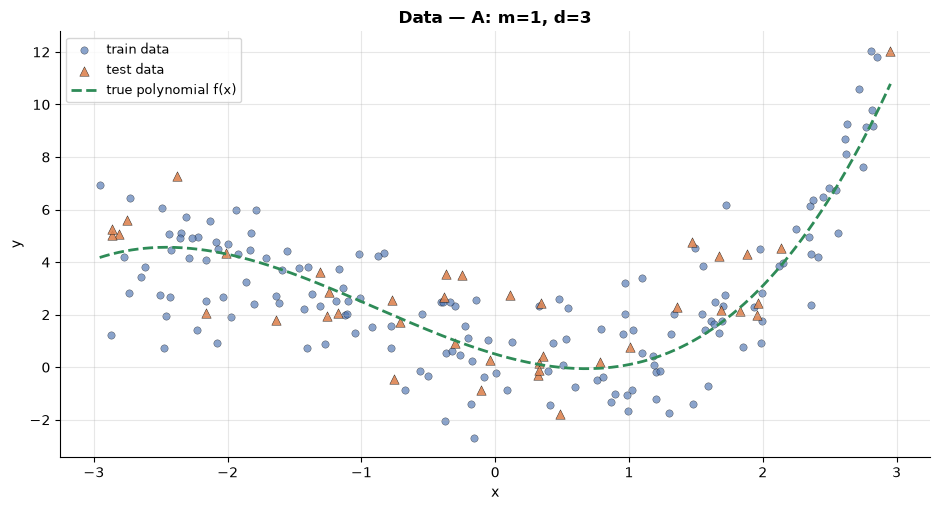

In [20]:
visualize(exp_A, "data")

> **Observation** — The noise-free curve (green) starts at about 4.5 near $x=-2.5$, falls to a minimum of about 0 near $x\approx0.7$ and then rises steeply to about 11 at $x=3$. The 200 samples scatter vertically by about $\pm1.5$ around it, with the same spread everywhere. Train (blue) and test (orange) points are mixed over the whole range, so the test set does not require extrapolation. Observed $y$ ranges from $-2.7$ to $12.0$.
>
> **Conclusion** — The signal is clearly cubic but the noise is large compared with the dip around $x\approx0.7$. With $\mathrm{Var}(y)\approx7.4$ the best possible $R^2$ is about $1-1.5^2/7.4\approx0.70$ on the whole sample (0.63 on this particular test split); no model can honestly beat an RMSE of about 1.5.

### A.2 Model prediction: fitted curve

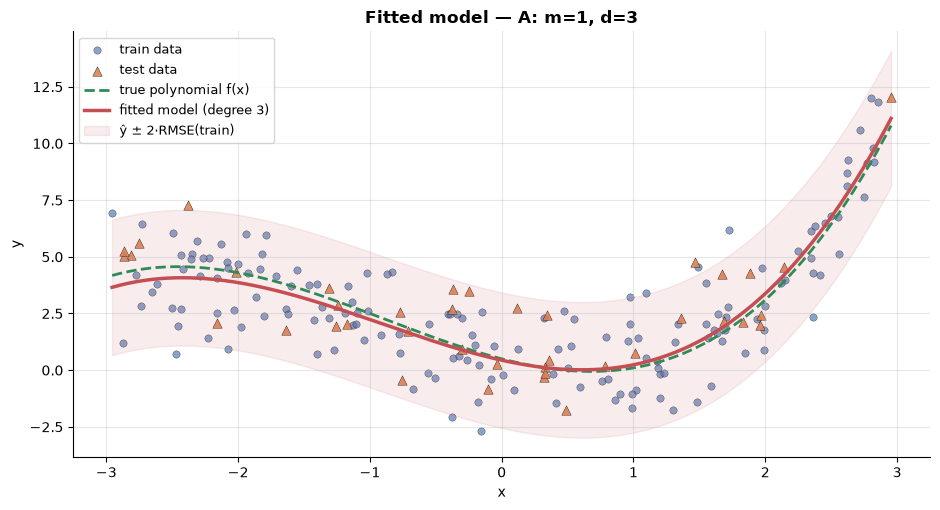

In [21]:
visualize(exp_A, "fit")

> **Observation** — The fitted degree-3 curve (red) follows the true curve (green) over the whole range: it reproduces the decline, the flat minimum and the steep rise. The visible deviations are small and sit at the left edge ($x\approx-3$, fit $\approx3.7$ vs. true $\approx4.2$) where there are fewer points. The shaded band $\hat y\pm2\,\mathrm{RMSE}$ ($\approx\pm3$) contains almost every observation.
>
> **Conclusion** — Degree 3 is flexible enough for this data and not more: the model captures all the structure and the remaining scatter is noise. Edge deviations are the usual higher variance of polynomial fits at the boundary of the data.

### A.3 Predicted vs. actual

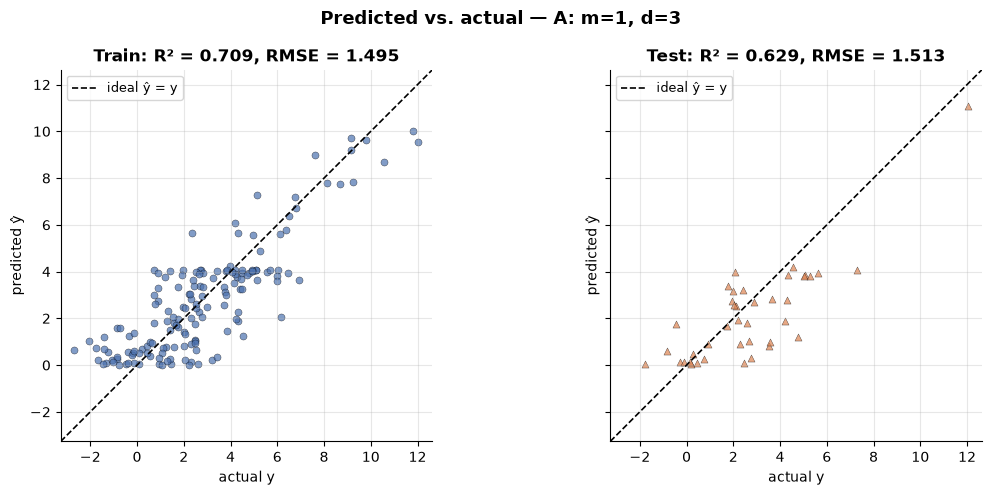

In [22]:
visualize(exp_A, "pred_vs_actual")

> **Observation** — Train: $R^2=0.709$, RMSE $=1.495$. Test: $R^2=0.629$, RMSE $=1.513$. Points scatter around the diagonal in both panels with the same spread, mostly along the *actual-y* direction (the predictions occupy a narrower range than the observations, which is typical for regression to the mean). The one large test point (actual $\approx12$) is predicted well.
>
> **Conclusion** — Train and test RMSE are practically equal (ratio 1.01), i.e. no over-fitting. The lower test $R^2$ comes from the test split having a smaller spread of $y$ (it is $R^2=0.630$ even for the *true* function on the same points, see section 8.1).

### A.4 Residual diagnostics

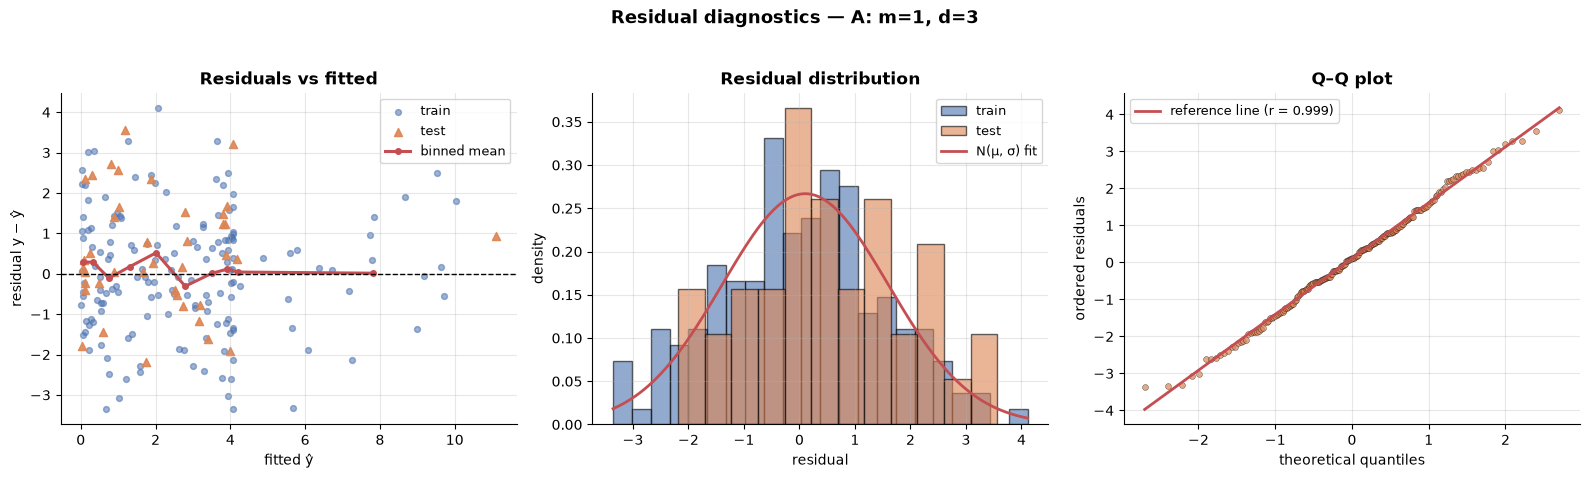

In [23]:
visualize(exp_A, "residuals")

> **Observation** — Residuals vs. fitted: a patternless cloud around zero; the binned mean stays within about $\pm0.5$ and no funnel is visible (Spearman $\rho(|e|,\hat y)\approx0.00$). The histogram is bell-shaped and the Q–Q points lie on the line ($r=0.999$; Shapiro–Wilk $p=0.86$, skew $+0.03$, excess kurtosis $-0.29$). The test residuals are slightly shifted to the positive side (mean $+0.52$).
>
> **Conclusion** — All least-squares assumptions are satisfied and no systematic curvature is left, so there is no reason to add terms. The test shift is a sampling effect of only 40 points (standard error $\approx0.24$): the true function has a mean residual of $+0.43$ on the same points.

### A.5 Estimated vs. true coefficients

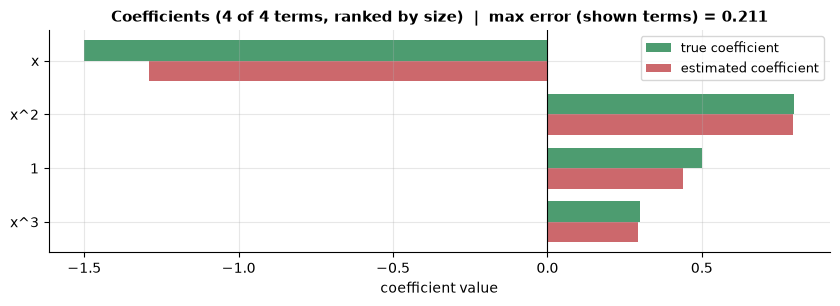

In [24]:
visualize(exp_A, "coefficients")

> **Observation** — Estimated and true bars are almost identical for $x^2$ (0.795 vs. 0.800) and $x^3$ (0.292 vs. 0.300); the intercept (0.440 vs. 0.500) and the linear coefficient ($-1.290$ vs. $-1.500$) show the largest differences.
>
> **Conclusion** — Coefficients of the highest-order terms are estimated most precisely here because $x^2$ and $x^3$ vary the most over $[-3,3]$. The lower-order coefficients carry larger uncertainty, so interpret individual coefficients with care and judge a polynomial mainly by its *predictions*.

### A.6 Effect of the polynomial degree (under-fit, good fit, over-fit)

With 160 samples even degree 12 is fairly harmless *inside* the data range (see the degree sweep in section 8.3). To expose the variance of a flexible model we repeat the experiment with only **40 samples** (32 for training).

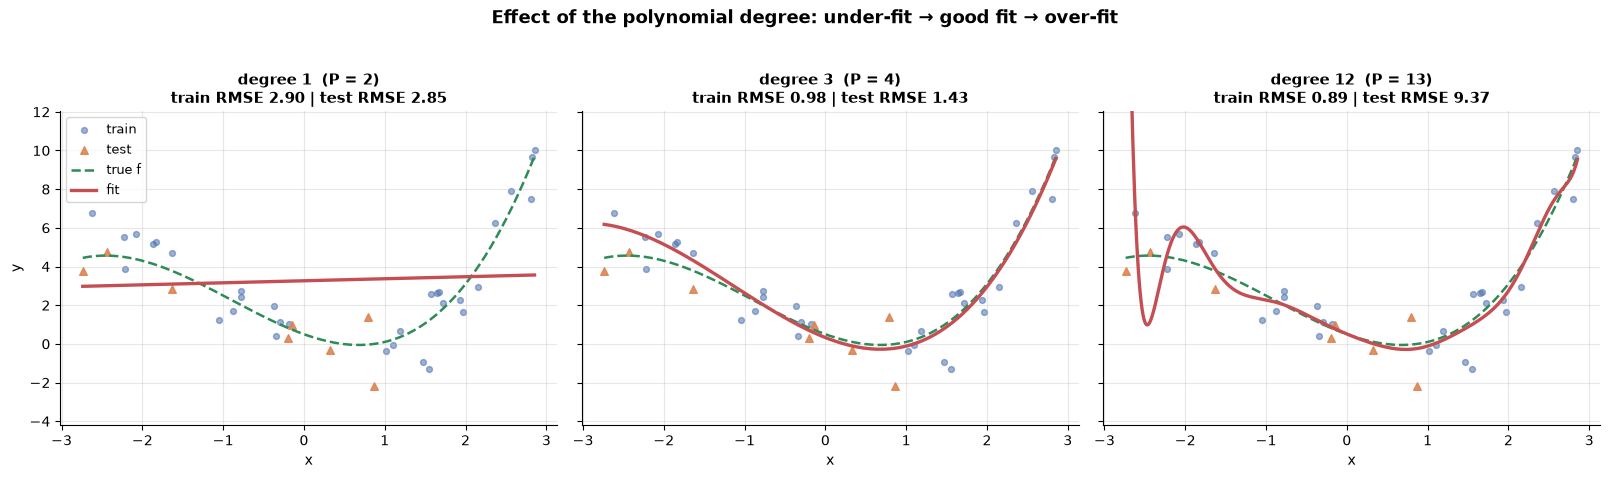

In [25]:
# same model, but only 40 samples, so that the variance of a flexible model becomes visible
plot_degree_comparison(replace(cfg_A, n_samples=40, name="A with n = 40"), degrees=(1, 3, 12))

> **Observation** — With only 40 samples (32 for training): **degree 1** is a nearly horizontal line with train RMSE 2.90 and test RMSE 2.85 (*under-fit*; it misses both bends). **Degree 3** has train RMSE 0.98 and test RMSE 1.43 (close to the noise level of 1.5 — the training noise happens to be a little small). **Degree 12** pushes train RMSE down to 0.89 but test RMSE up to **9.37**: the curve oscillates between points and shoots away at the edges.
>
> **Conclusion** — The classic bias–variance picture: too low a degree gives high error on both sets; the right degree gives similar, noise-level errors; too high a degree *lowers* the training error and *raises* the test error. Training error can never be used to select the degree. Over-fitting becomes dangerous when the number of terms is large relative to the number of samples (13 terms for 32 points here).

## 7.B  Two features, degree 3 — 3-D surface

With $m=2$ the data and the model live in 3-D: the model is a **surface** $\hat y(x_1,x_2)$ and each sample is a point above or below it. The plots below are interactive (rotate, zoom, hover).

In [26]:
# ---------------- Experiment B : 2 features, degree 3  (3-D plots) ----------------
cfg_B = Config(name="B: m=2, d=3", n_samples=300, n_features=2, true_degree=3, noise_std=1.0)
exp_B = run_experiment(cfg_B)

print(f"X {exp_B.data.X.shape} | y {exp_B.data.y.shape} | P = {cfg_B.n_terms_model} terms | train/test = {len(exp_B.idx_train)}/{len(exp_B.idx_test)}")
display(coefficient_table(exp_B).round(3))

X (300, 2) | y (300,) | P = 10 terms | train/test = 240/60


,estimated,true,abs_error
term,,,
1,-0.209,-0.045,0.164
x1,0.522,0.523,0.001
x2,0.888,0.807,0.082
x1^2,0.242,0.221,0.021
x1 x2,0.454,0.463,0.009
x2^2,0.311,0.282,0.029
x1^3,0.196,0.183,0.012
x1^2 x2,-0.179,-0.193,0.014
x1 x2^2,0.099,0.116,0.018


> **Observation** — 300 samples with two features, 10 polynomial terms and 24 training samples per term. Target values range from $-8.5$ to $12.9$ ($\sigma_y\approx3.8$) with noise $\sigma=1$. All 10 coefficients are recovered; the interaction $x_1x_2$ is $0.454$ vs. $0.463$, and the largest error ($0.16$) is on the intercept.
>
> **Conclusion** — The estimation works unchanged for two features; the interaction term, which a model without cross terms could not represent, is estimated accurately.

### B.1 Data and the true surface

In [27]:
visualize(exp_B, "data")

> **Observation** — The surface rises steeply along $x_1$ (from about $-10$ to about $+13$) and its slope depends on $x_2$: the surface is *twisted*, the $x_1$ effect is much stronger for large $x_2$ than for small $x_2$. Points lie about $\pm1$ above and below the surface (noise $\sigma=1$). Train and test points are intermixed.
>
> **Conclusion** — The data contain curvature in each feature plus an interaction, so a plane (or a polynomial without cross terms) would fit badly. This is exactly the case where degree 3 with 10 terms is needed. The figure is interactive: rotate it to see the twist.

### B.2 Model prediction: fitted surface vs. true surface

In [28]:
visualize(exp_B, "fit")

> **Observation** — The fitted surface (colour) and the true surface (translucent green) are practically on top of each other over the whole $[-3,3]^2$ square; only at the extreme corners can a thin green edge be seen. Both train points (blue) and test points (orange diamonds) lie at similar distances above and below the surface.
>
> **Conclusion** — The degree-3 model recovers the underlying surface; the test RMSE ($1.061$) equals the RMSE of the true function on the same test points ($1.061$), i.e. the model has reached the noise floor.

### B.3 Contour view of the fitted surface

In [29]:
visualize(exp_B, "contour")

> **Observation** — The iso-lines are curved and fan out to the right: the response is lowest in the corner $(x_1,x_2)=(-3,3)$ (about $-10$) and highest on the right edge (above 12). Points are coloured with the same scale as the surface; almost all of them blend into the background colour, and train and test points behave alike.
>
> **Conclusion** — Colour agreement between points and surface means that the model explains the data locally everywhere, not only on average. Curved iso-lines confirm non-linearity, and their unequal spacing along $x_1$ reflects the steeper response at large $x_1$.

### B.4 Partial dependence

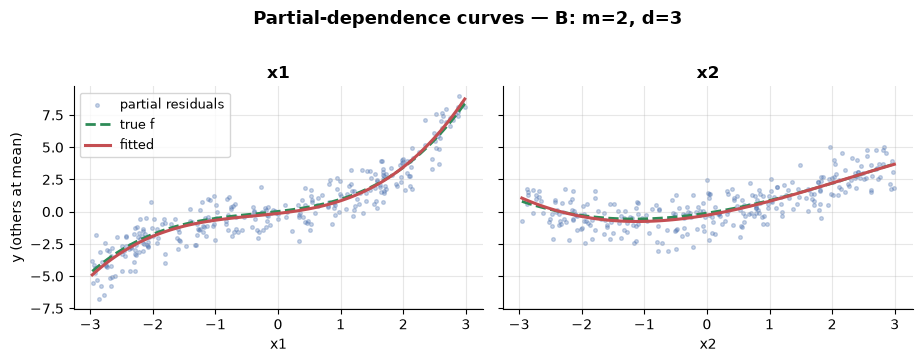

In [30]:
visualize(exp_B, "pdp")

> **Observation** — $x_1$ has an S-shaped (cubic) effect from about $-5$ at $x_1=-3$ to about $+9$ at $x_1=3$, flat near 0. $x_2$ has a smaller, U-shaped effect (about $1$ at $-3$, minimum $\approx-0.6$ near $-1.5$, then up to $\approx3.7$ at $x_2=3$). Fitted (red) and true (green dashed) curves overlap; partial-residual points scatter by about $\pm1$.
>
> **Conclusion** — $x_1$ is the dominant feature. $x_2$ has a smaller marginal effect at the mean of $x_1$, but it matters strongly through the interaction seen in the surface plot: partial-dependence curves alone hide interactions, so use them together with the slice and contour views.

### B.5 Predicted vs. actual

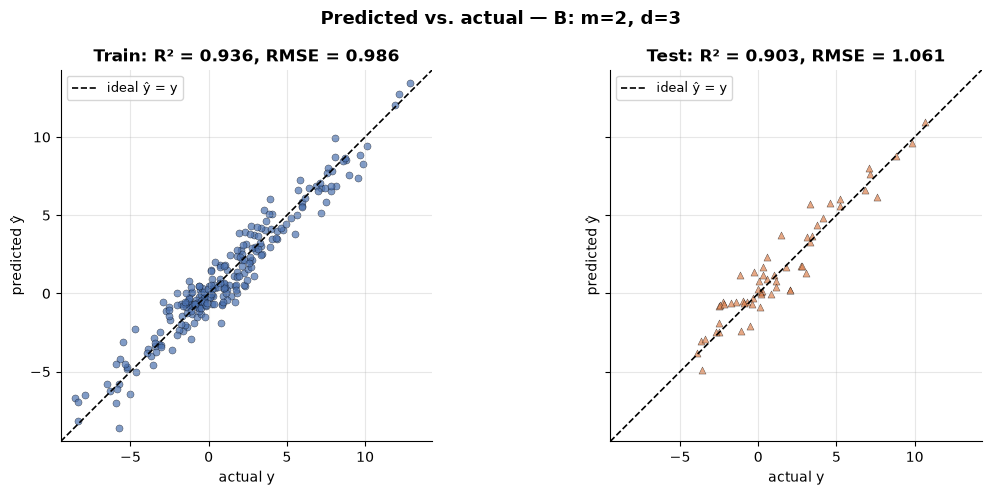

In [31]:
visualize(exp_B, "pred_vs_actual")

> **Observation** — Points follow the diagonal tightly from about $-9$ to $+13$. Train: $R^2=0.936$, RMSE $=0.986$; test: $R^2=0.903$, RMSE $=1.061$. The test scatter is a little wider, as expected for unseen data.
>
> **Conclusion** — Test/train RMSE ratio is 1.08, a small and normal generalisation gap with 24 samples per term. Test RMSE ($1.06$) is close to the true noise level $\sigma=1$.

### B.6 Residual diagnostics

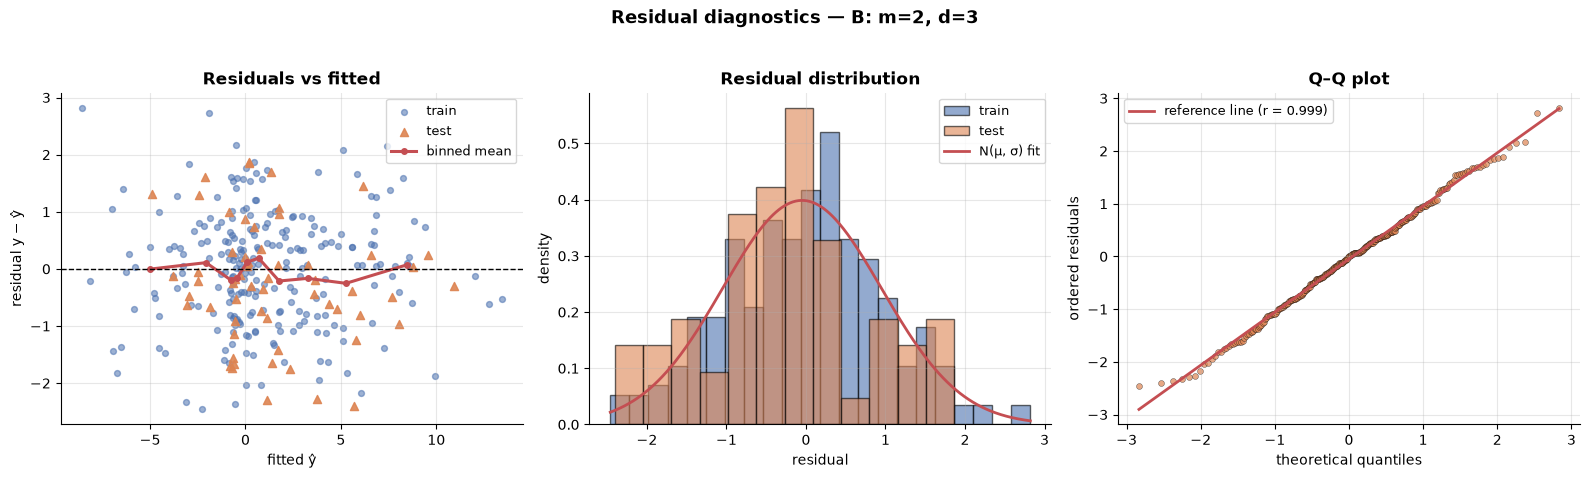

In [32]:
visualize(exp_B, "residuals")

> **Observation** — Residuals vs. fitted show no trend (binned mean within $\pm0.3$) and constant width over the whole range $-9$ to $+13$. The histogram is bell-shaped and the Q–Q plot is straight ($r=0.999$; Shapiro–Wilk $p=0.82$, skew $0.00$, excess kurtosis $-0.18$).
>
> **Conclusion** — The residuals are consistent with pure Gaussian noise: no missing terms, no heteroscedasticity, no outliers. The estimated noise level $\hat\sigma=1.008$ matches the true $\sigma=1.000$.

### B.7 Residuals against each feature

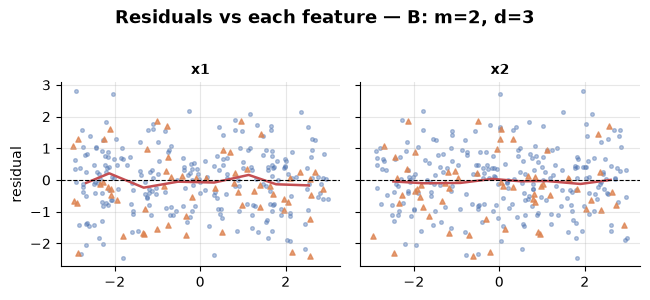

In [33]:
visualize(exp_B, "residuals_vs_features")

> **Observation** — Against both $x_1$ and $x_2$ the residuals form a horizontal band around 0 and the binned mean line stays flat within about $\pm0.2$; test points (orange) are spread like the training points.
>
> **Conclusion** — No feature carries unexplained structure, so no additional power or interaction involving $x_1$ or $x_2$ is needed — consistent with the true degree 3.

### B.8 Estimated vs. true coefficients

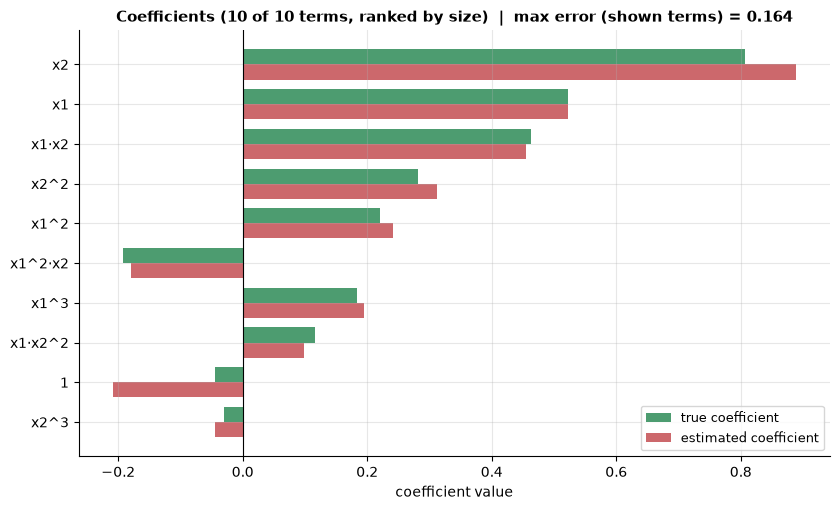

In [34]:
visualize(exp_B, "coefficients")

> **Observation** — Every one of the 10 estimated coefficients lies close to its true value; the largest errors are the intercept ($-0.209$ vs. $-0.045$, error $0.16$) and $x_2$ ($0.888$ vs. $0.807$, error $0.08$); all others are within $0.03$, including the interaction terms.
>
> **Conclusion** — With 24 samples per term and $\sigma=1$ the full cubic surface, interactions included, is identified accurately. Terms that overlap (the constant with the even powers, $x_2$ with $x_2^3$) are the least certain ones.

## 7.C  Five features, degree 2 — from $n$ dimensions to 3-D

With $m=5$ the model is a hyper-surface in 6-D. We look at it through **slices** (two features vary, the rest at their mean), **partial-dependence curves** and a **PCA projection**.

In [35]:
# ---------------- Experiment C : 5 features, degree 2  (n-D -> 3-D) ----------------
cfg_C = Config(name="C: m=5, d=2", n_samples=400, n_features=5, true_degree=2, noise_std=0.5)
exp_C = run_experiment(cfg_C)

print(f"X {exp_C.data.X.shape} | y {exp_C.data.y.shape} | P = {cfg_C.n_terms_model} terms | samples per term (train) = {len(exp_C.idx_train)/cfg_C.n_terms_model:.1f}")
display(coefficient_table(exp_C).round(3).head(8))

X (400, 5) | y (400,) | P = 21 terms | samples per term (train) = 15.2


,estimated,true,abs_error
term,,,
1,0.586,0.685,0.100
x1,-0.091,-0.107,0.016
x2,0.903,0.906,0.003
x3,0.317,0.302,0.015
x4,-0.751,-0.768,0.017
x5,0.807,0.770,0.037
x1^2,0.019,-0.011,0.030
x1 x2,-0.360,-0.358,0.001


> **Observation** — 400 samples, 5 features and 21 terms (15 training samples per term). The first rows of the coefficient table show that main effects ($x_2$: $0.903$ vs. $0.906$; $x_4$: $-0.751$ vs. $-0.768$) and interactions ($x_1x_2$: $-0.360$ vs. $-0.358$) are all recovered.
>
> **Conclusion** — The same `Config` / `run_experiment` calls handle five features; nothing in the code depends on $m$.

### C.1 Data: slice through the true function

In [36]:
visualize(exp_C, "data")

> **Observation** — Of the five features the plot automatically selects the two with the largest effect on the response ($x_2$ and $x_4$). The slice of the true function is a smooth, curved surface. The other three features are fixed at their mean, and the points are *partial* values (true slice value plus the noise of each sample), so they scatter by the noise only ($\sigma=0.5$).
>
> **Conclusion** — A 6-D function cannot be drawn completely, but a slice through the mean shows its shape in the two most influential directions. Always read it together with the partial-dependence and the PCA views.

### C.2 Model prediction: fitted slice surface

In [37]:
visualize(exp_C, "fit")

> **Observation** — The fitted slice over $x_2$ and $x_5$ (the two features with the largest effect on the *fitted* model) is a curved surface (concave in $x_2$, convex in $x_5$) spanning roughly $-5$ to $+5$; the true surface (translucent green) hugs it. Points lie within about $\pm0.5$ of the surface, train and test alike.
>
> **Conclusion** — Even though the model has 21 terms and five inputs, along these two directions it reproduces the truth closely, and the tight scatter shows the noise level is small compared with the signal ($R^2\approx0.985$).

### C.3 Choosing another pair of features

In [38]:
visualize(exp_C, "fit", pair=(0, 4))

> **Observation** — Choosing the pair $(x_1,x_5)$ with `pair=(0, 4)` gives a *twisted* surface: along $x_1$ the response rises for negative $x_5$ and falls for positive $x_5$, although $x_1$ has almost no effect on its own (see the flat $x_1$ curve in C.5). The fitted and true surfaces still coincide.
>
> **Conclusion** — This is the signature of the interaction term $x_1x_5$ (true $-0.45$, estimated $-0.46$): a feature can be unimportant on average yet matter in combination with another one. This is why several slices (or the coefficient plot) should be inspected for $m>2$.

### C.4 Contour of the slice

In [39]:
visualize(exp_C, "contour")

> **Observation** — The contour lines of the slice are smooth and curved, with the colour of almost every point matching the surface colour behind it. Both train points and test points follow the same pattern.
>
> **Conclusion** — A flat view of the same slice confirms that the model explains the data locally everywhere in the plane; it is a convenient alternative to the 3-D view when exact positions matter.

### C.5 Partial dependence of every feature

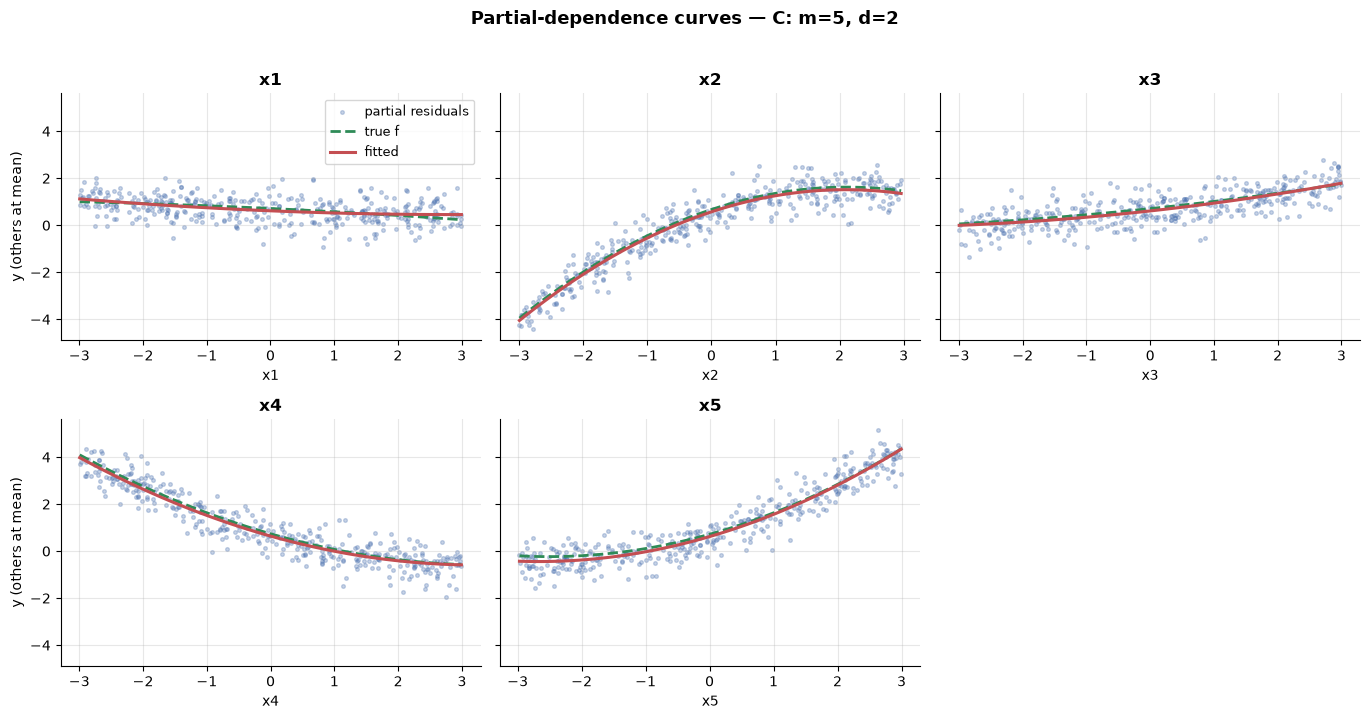

In [40]:
visualize(exp_C, "pdp")

> **Observation** — The five feature effects (others at their mean) are very different: $x_2$ rises steeply and saturates (from $-4$ to $+1.6$), $x_4$ falls convexly (from $4$ to $-0.6$), $x_5$ rises convexly (from $-0.3$ to $4.4$), $x_3$ is nearly linear and small, and $x_1$ is almost flat ($1.1\to0.4$). Fitted and true curves overlap almost perfectly (largest visible gap at the left end of $x_5$, about 0.2).
>
> **Conclusion** — The model correctly identifies the shape and importance of every feature. Partial-dependence curves give a compact "n-D to 2-D" summary, but they show only average-at-the-mean effects and cannot reveal interactions such as $x_1x_5$.

### C.6 PCA projection: 5-D inputs in 3-D, coloured by actual and predicted $y$

In [41]:
visualize(exp_C, "projection")

> **Observation** — The three principal components keep only $63\%$ of the input variance (22 % + 21 % + 20 %) because the five features are independent and equally spread. The left panel (actual $y$) and the right panel (predicted $\hat y$) have the same colour pattern: high values (yellow, up to about $+14$) are concentrated in one corner of the cloud while the lowest values (dark, down to about $-15$) lie in the opposite, central-right region; no point changes its colour noticeably between the panels.
>
> **Conclusion** — The match of colours across the whole 5-D cloud confirms the fit is good *globally*, not only on a single slice. PCA cannot compress independent features, so this view is a sanity check; the slice and partial-dependence plots remain the tools for interpretation.

### C.7 Predicted vs. actual

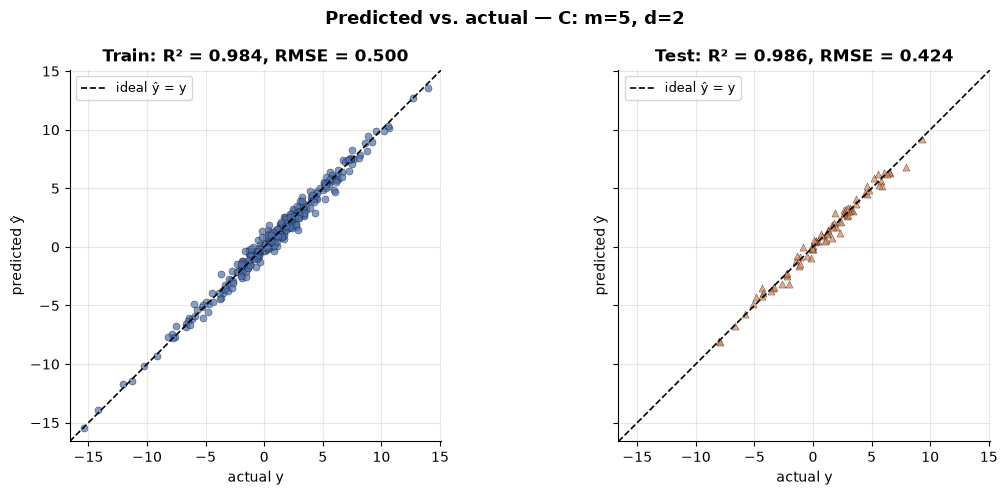

In [42]:
visualize(exp_C, "pred_vs_actual")

> **Observation** — Predictions hug the diagonal over a wide range ($-15$ to $+14$). Train: $R^2=0.984$, RMSE $=0.500$; test: $R^2=0.986$, RMSE $=0.424$.
>
> **Conclusion** — The train RMSE equals the true noise $\sigma=0.5$. The test RMSE is even lower, which does not mean the model is better than the truth: it happens that these 80 test points carry less noise (the true function reaches $0.434$ on them). Test/train RMSE ratio $0.85$ — no over-fitting.

### C.8 Residual diagnostics

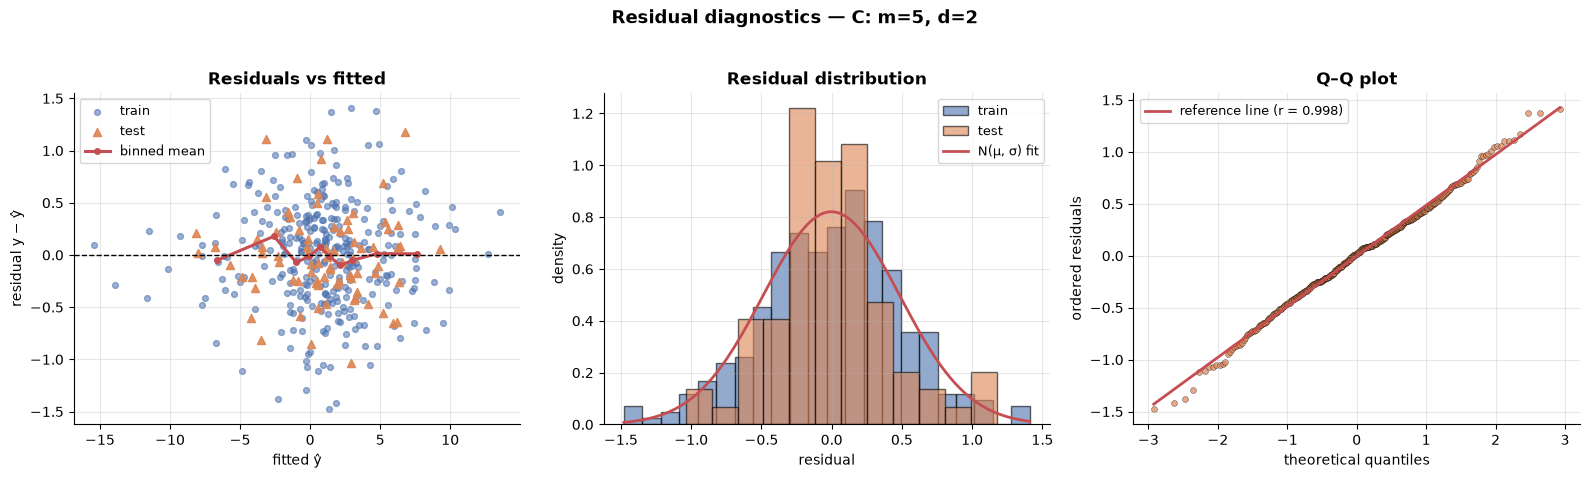

In [43]:
visualize(exp_C, "residuals")

> **Observation** — Residuals are a random cloud around 0 within about $\pm1.5$ ($\approx\pm3\sigma$), the binned mean is within $\pm0.2$ of zero, and the spread is constant over the entire fitted range ($-15$ to $+13$). Q–Q $r=0.998$; Shapiro–Wilk $p=0.56$; skew $-0.04$; excess kurtosis $+0.32$.
>
> **Conclusion** — Residuals behave like Gaussian noise with $\hat\sigma=0.518$ (true $0.5$): the degree-2 model is correctly specified for this data.

### C.9 Residuals against each feature

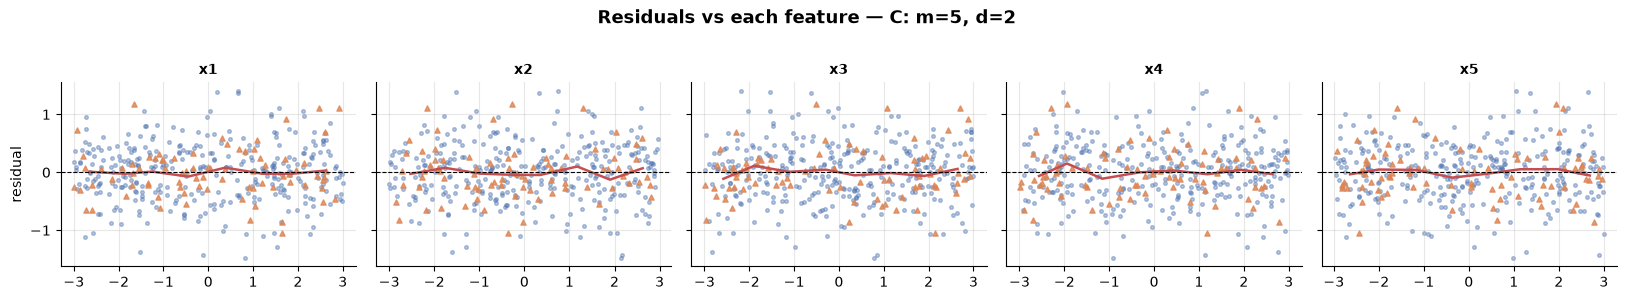

In [44]:
visualize(exp_C, "residuals_vs_features")

> **Observation** — For each of the five features the residuals form a flat horizontal band and the binned mean (red) stays within about $\pm0.15$ of zero.
>
> **Conclusion** — No feature shows leftover curvature, so no higher power or additional interaction is needed — consistent with true degree 2. This per-feature check scales to any $m$.

### C.10 Estimated vs. true coefficients

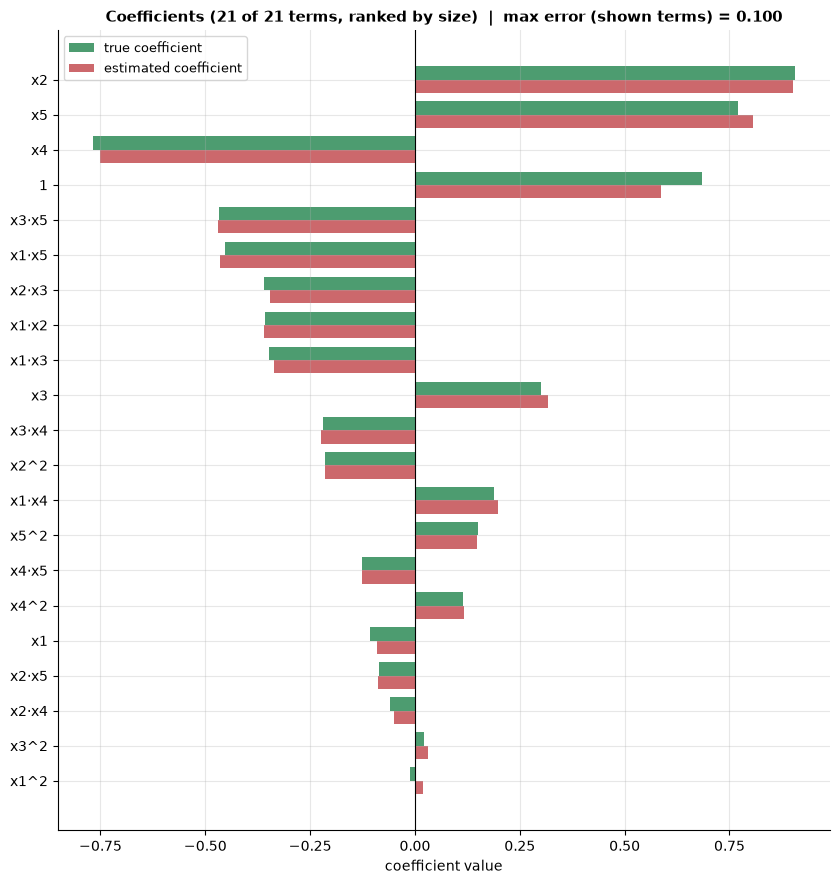

In [45]:
visualize(exp_C, "coefficients")

> **Observation** — The 21 estimated coefficients track the true ones closely, including the 10 interaction terms; maximal error $0.100$ (the intercept: $0.586$ vs. $0.685$), the next largest $0.037$ ($x_5$), and all the others are below $0.04$. The tiny terms $x_1^2$ and $x_3^2$ (true size below $0.03$) are estimated with errors of at most $0.03$ (for $x_1^2$ even with the opposite sign, which is irrelevant at that size).
>
> **Conclusion** — With 15 samples per term and $\sigma=0.5$ all main effects, squares and interactions are recovered to within about $0.04$. The intercept is again the least certain term because it is correlated with the squared terms (their mean is non-zero).

## 7.D  Ten features, degree 2 — high-dimensional stress test

66 polynomial terms, 800 samples. The *same* calls work unchanged.

In [46]:
# ---------------- Experiment D : 10 features, degree 2  (stress test) ----------------
cfg_D = Config(name="D: m=10, d=2", n_samples=800, n_features=10, true_degree=2, noise_std=1.0)
exp_D = run_experiment(cfg_D)
print(f"X {exp_D.data.X.shape} | P = {cfg_D.n_terms_model} terms | samples per term (train) = {len(exp_D.idx_train)/cfg_D.n_terms_model:.1f}")

X (800, 10) | P = 66 terms | samples per term (train) = 9.7


> **Observation** — 800 samples, 10 features and 66 terms ($\approx9.7$ training samples per term), noise $\sigma=1$.
>
> **Conclusion** — This is close to the minimum sample size recommended in section 1.8. With $d=3$ the model would have 286 terms — only 2.2 training samples per term — and a much larger variance; the choice $d=2$ is deliberate.

### D.1 Model prediction: fitted slice

In [47]:
visualize(exp_D, "fit")

> **Observation** — The slice over the two strongest features ($x_3$ and $x_{10}$) is a curved surface from about $-8$ to $+5$; the fitted and true surfaces match, differing only slightly at the edges. The scatter around the surface is about $\pm1$ and larger than in experiment C, as expected from $\sigma=1$ and the remaining 8 features being fixed at their mean.
>
> **Conclusion** — The visualisation routine copes with ten features by choosing the pair automatically and labelling the figure as a slice; other pairs can be requested with `pair=(i, j)`.

### D.2 Predicted vs. actual

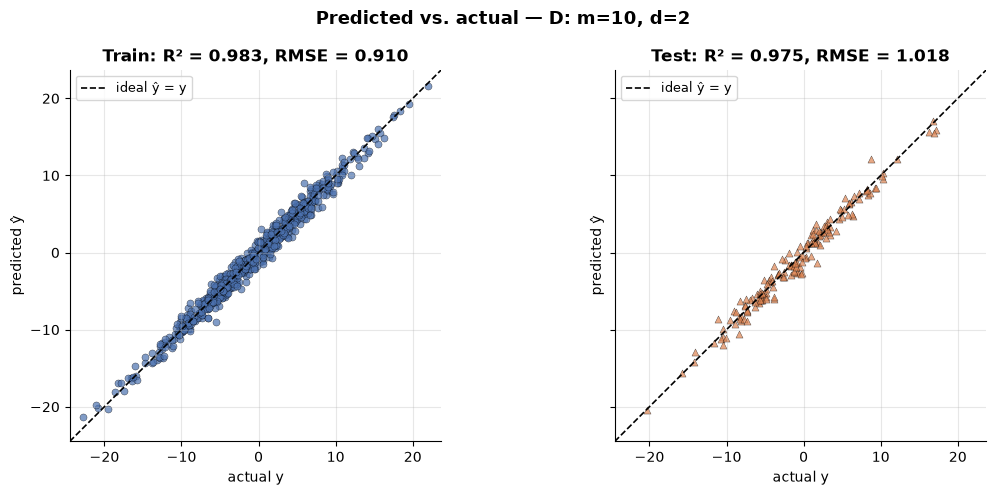

In [48]:
visualize(exp_D, "pred_vs_actual")

> **Observation** — Points follow the diagonal tightly over a range of $\pm22$. Train: $R^2=0.983$, RMSE $=0.910$; test: $R^2=0.975$, RMSE $=1.018$.
>
> **Conclusion** — The training RMSE (0.91) is below the noise level $\sigma=1$ and the test RMSE (1.02) is slightly above it: this is exactly what the theory predicts for a model with $P/n=66/640\approx0.10$ (train $\approx\sigma\sqrt{1-P/n}=0.95$, test $\approx\sigma\sqrt{1+P/n}=1.05$). The generalisation gap is small (ratio 1.12) but larger than in the experiments with fewer terms per sample.

### D.3 Residual diagnostics

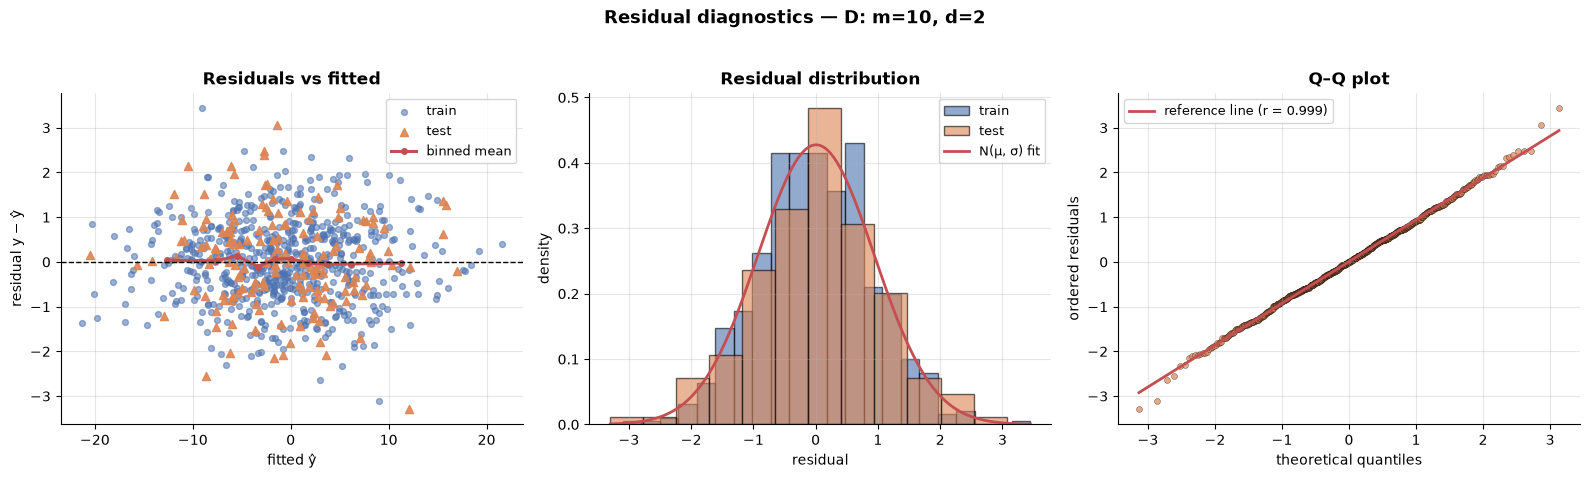

In [49]:
visualize(exp_D, "residuals")

> **Observation** — Residuals show no trend vs. the fitted values, constant spread, a bell-shaped histogram and a straight Q–Q line (Shapiro–Wilk $p=0.94$, skew $+0.03$, excess kurtosis $+0.25$); $\hat\sigma=0.961$ against the true $1.0$.
>
> **Conclusion** — Even with 66 parameters the residuals remain well behaved, so the least-squares model is adequate for this ten-feature problem.

### D.4 Estimated vs. true coefficients

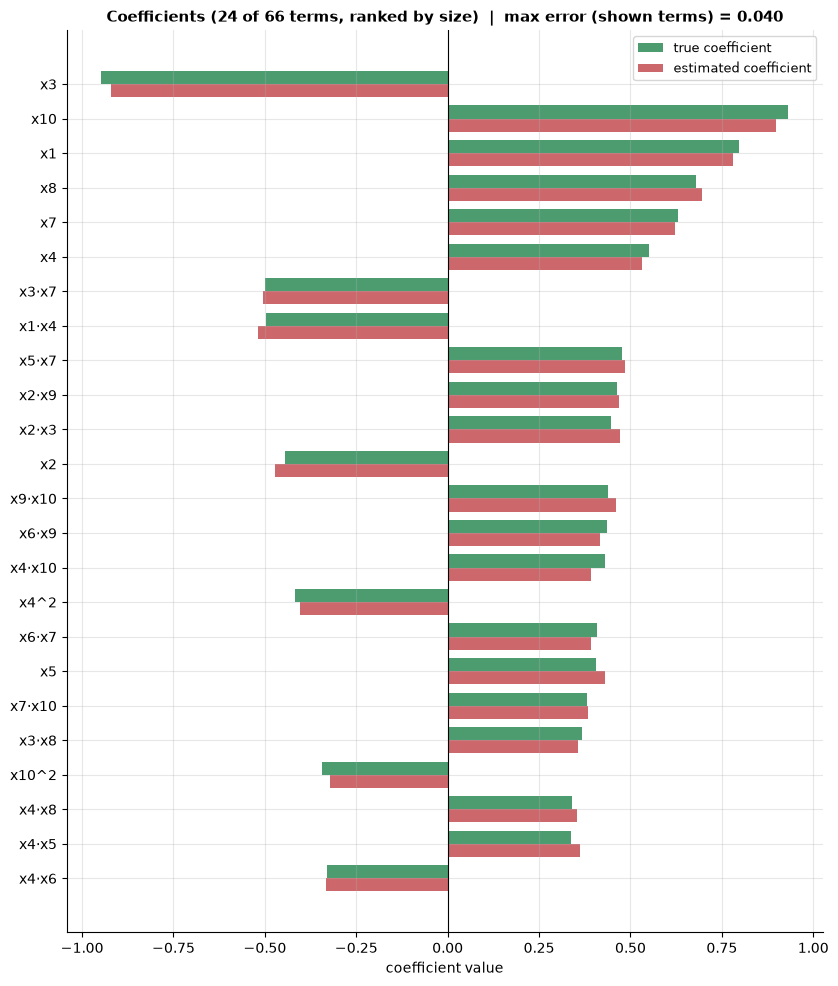

In [50]:
visualize(exp_D, "coefficients")

> **Observation** — The 24 largest true coefficients (out of 66) are matched by the estimates with a maximal error of $0.04$; the largest error among all 66 terms is the intercept ($-0.256$ vs. $0.119$, error $0.37$).
>
> **Conclusion** — With ten features the large effects are recovered reliably, while the intercept is the weakest estimate: it is correlated with the ten squared terms, whose means are far from zero. When predictions matter more than interpretation this is harmless.

<a id="metrics-all"></a>
---
# 8. All metric evaluations in one place

Everything numeric is collected here: the full metric table for every experiment (train, test and oracle rows), the automatic diagnostic report, and the degree-selection study with cross-validation.

## 8.1 Full metric table — all experiments, all splits

In [51]:
experiments = {"A (m=1, d=3)": exp_A, "B (m=2, d=3)": exp_B, "C (m=5, d=2)": exp_C, "D (m=10, d=2)": exp_D}
metrics_all = compare(experiments)
style_metrics(metrics_all)

**How to read the table.** Rows are grouped by experiment; within each, `train` and `test` are the model, and `oracle` is the true function evaluated on the same test targets (the best possible result for that noise level). *MAPE / sMAPE* are unreliable here because $y$ crosses zero (see section 1.9).

> **Observation** —
> (1) *Noise floor reached.* Test RMSE equals the oracle RMSE in A ($1.513$ vs. $1.511$) and B ($1.061$ vs. $1.061$); in C ($0.424$ vs. $0.434$) the model is on par with the truth; D ($1.018$ vs. $0.931$) is the only case with a visible gap ($+9\,\%$).
> (2) *Why the gap in D.* The expected test RMSE of least squares is $\approx\sigma\sqrt{1+P/n}$: $1.52$ (A), $1.02$ (B), $0.52$ (C), $1.05$ (D) — matching the observed values; the penalty is largest where $P/n$ is largest.
> (3) *Train vs. test.* Train RMSE is at or just below $\sigma$ ($\approx\sigma\sqrt{1-P/n}$) and the mean training residual is exactly $0$, as the normal equations require.
> (4) *Adjusted $R^2$* is below $R^2$ and the difference grows with $P/n$ (A: $0.598$ vs. $0.629$; D: $0.958$ vs. $0.975$ on the test set).
> (5) *MAPE / sMAPE* are $48$–$202\,\%$ and $30$–$78\,\%$ respectively, even for the oracle — meaningless here because $y$ crosses zero. The maximum errors are about $2.4$–$3.4\,\sigma$ (e.g. $4.11=2.7\sigma$ in A-train, $3.45=3.4\sigma$ in D-train), as expected for samples of this size drawn from a normal distribution.
>
> **Conclusion** — Judge a model against the *oracle/noise floor*, not against $R^2=1$: $R^2$ ranges from $0.63$ (A) to $0.99$ (C) only because the noise-to-signal ratio differs between the experiments, not because the model quality differs. RMSE and the train/test ratio are the primary metrics here; $R^2$ and adjusted $R^2$ are secondary; MAPE should not be used for data that cross zero.

## 8.2 Automatic diagnostic report

In [52]:
for e in experiments.values():
    diagnose(e)
    print()

━━ A: m=1, d=3 ━━  (m=1, model degree=3, P=4 terms, n_train=160)
• Generalisation : RMSE train 1.495 → test 1.513 (ratio 1.01) → no sign of over-fitting; R² train 0.709 vs test 0.629 (gap +0.081)  [R² gap with RMSE ratio ≈ 1: the test split simply has a smaller spread of y]
• Noise level    : σ̂ (from train residuals) = 1.514  vs true σ = 1.500  |  test RMSE = 1.513  |  noise-ceiling R² (test) = 0.630
• Residual shape : max |bin-mean residual| = 0.46·std → no systematic curvature left
• Heteroscedast. : Spearman(|res|, ŷ) = -0.00 → roughly constant variance
• Normality      : Shapiro-Wilk p = 0.862, skew = +0.03, excess kurtosis = -0.29 → residuals consistent with a normal distribution
• Conditioning   : κ(Φ) = 1.5e+01, samples per term = 40.0 → well conditioned

━━ B: m=2, d=3 ━━  (m=2, model degree=3, P=10 terms, n_train=240)
• Generalisation : RMSE train 0.986 → test 1.061 (ratio 1.08) → no sign of over-fitting; R² train 0.936 vs test 0.903 (gap +0.033)  [R² gap with RMSE ratio ≈ 1:

> **Observation** — All four experiments pass every automatic check: constant variance (|Spearman| $\le0.04$), no residual structure (max binned mean $\le0.46\,\sigma$), normal residuals (Shapiro–Wilk $p\ge0.56$), well-conditioned design matrices ($\kappa=15$–$38$). The noise estimate $\hat\sigma$ is within $4\,\%$ of the true $\sigma$ in all cases. In A the $R^2$ gap is $+0.081$ although the RMSE ratio is $1.01$.
>
> **Conclusion** — The data were generated by exactly the assumed model, so a clean report is expected; on real data the same function will flag curvature, funnels, non-normality or ill-conditioning. The A example shows why the report judges over-fitting by the RMSE ratio: an $R^2$ gap alone can arise from a different spread of $y$ in the test split.

## 8.3 Degree selection with cross-validation

### Experiment A (1 feature, true degree 3)

,P terms,train RMSE,CV RMSE,CV std,test RMSE,train R²,test R²,test Adj R²
degree,,,,,,,,
1,2,2.753791,2.792535,0.197569,2.522272,0.013464,-0.031693,-0.058843
2,3,1.847407,1.897632,0.125707,1.629229,0.556007,0.569542,0.546274
3,4,1.494728,1.550708,0.092115,1.513448,0.709346,0.628549,0.597594
4,5,1.489817,1.553010,0.090421,1.479358,0.711253,0.645094,0.604533
5,6,1.484204,1.571749,0.139160,1.499829,0.713425,0.635204,0.581557
6,7,1.467947,1.560135,0.123352,1.509864,0.719669,0.630306,0.563089
7,8,1.466416,1.566167,0.117454,1.519626,0.720253,0.625510,0.543590
8,9,1.463031,1.573555,0.117946,1.523971,0.721543,0.623365,0.526169
9,10,1.461947,1.613246,0.184074,1.507411,0.721955,0.631506,0.520958


CV-selected degree: 3   (true degree = 3)


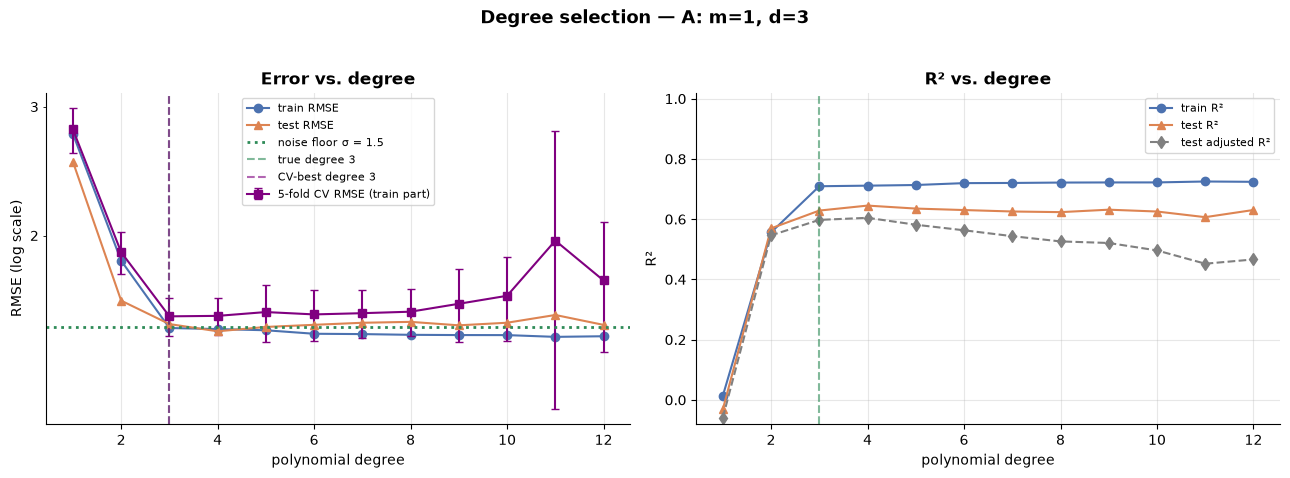

In [53]:
sweep_A = degree_sweep(cfg_A, degrees=range(1, 13))
display(sweep_A.style.format("{:.3f}", subset=[c for c in sweep_A.columns if c != "P terms"])
        .highlight_min(subset=["CV RMSE"], color="#c8e6c9").format({"P terms": "{:.0f}"}))
print(f"CV-selected degree: {sweep_A['CV RMSE'].idxmin()}   (true degree = {cfg_A.true_degree})")
plot_degree_sweep(sweep_A, cfg_A)

> **Observation** — CV RMSE drops from $2.79$ ($d=1$) to $1.90$ ($d=2$) and reaches its minimum of $1.551$ at $d=3$; for $d\ge4$ it stays flat or increases ($1.55$–$1.65$ up to $d=10$) and its fold-to-fold spread grows from $0.09$ to $0.81$ at $d=11$. Train RMSE keeps falling slightly ($1.495\to1.457$), whereas the test RMSE stays flat at $\approx1.48$–$1.56$ (the noise floor is $1.5$) for all $d\ge3$. Adjusted $R^2$ on the test set peaks at $d=3$–$4$ ($0.598$/$0.605$) and then declines to $0.47$.
>
> **Conclusion** — The "elbow" is at the true degree 3. Higher degrees buy no accuracy but add variance and instability (seen in the CV spread); with 160 samples they do not break the model inside the data range but they would extrapolate badly. Choose the smallest degree whose CV error is within one standard error of the minimum — here 3.

### Experiment B (2 features, true degree 3)

,P terms,train RMSE,CV RMSE,CV std,test RMSE,train R²,test R²,test Adj R²
degree,,,,,,,,
1,3,2.245232,2.292627,0.200585,2.294095,0.670393,0.548296,0.532446
2,6,1.414683,1.444542,0.192800,1.382398,0.869144,0.835980,0.820793
3,10,0.986314,1.039279,0.118055,1.061263,0.936393,0.903333,0.885933
4,15,0.981337,1.066597,0.124049,1.061544,0.937033,0.903282,0.873192
5,21,0.974347,1.115261,0.175124,1.090297,0.937927,0.897972,0.845649
6,28,0.954695,1.098251,0.144119,1.098654,0.940406,0.896401,0.808990
7,36,0.924016,1.284056,0.261670,1.176466,0.944174,0.881207,0.707968
8,45,0.907635,1.550528,0.620709,1.280761,0.946136,0.859211,0.446231


CV-selected degree: 3   (true degree = 3)


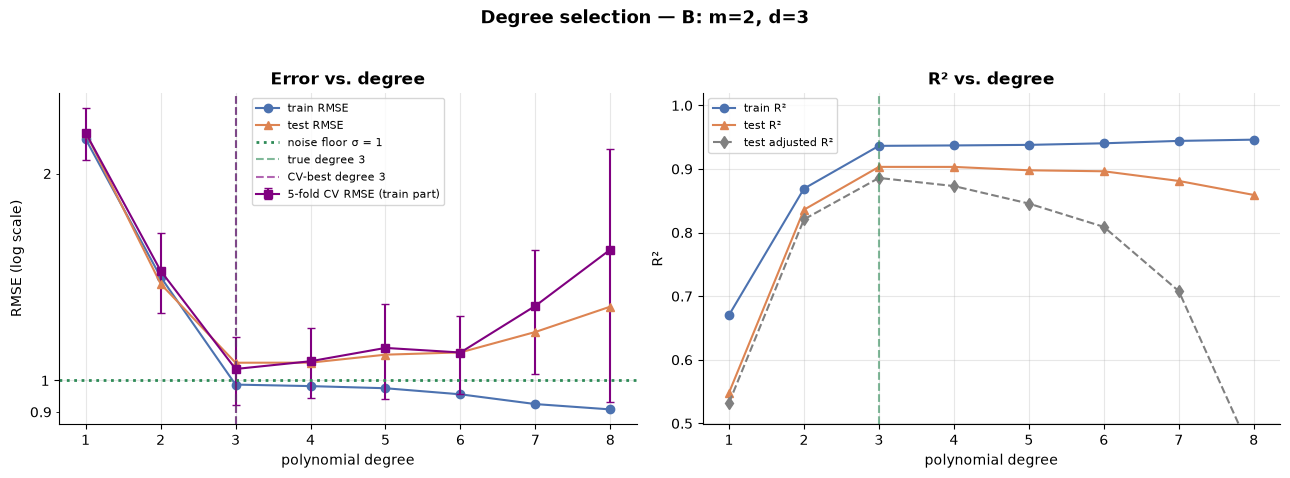

In [54]:
sweep_B = degree_sweep(cfg_B, degrees=range(1, 9))
display(sweep_B.style.format("{:.3f}", subset=[c for c in sweep_B.columns if c != "P terms"])
        .highlight_min(subset=["CV RMSE"], color="#c8e6c9").format({"P terms": "{:.0f}"}))
print(f"CV-selected degree: {sweep_B['CV RMSE'].idxmin()}   (true degree = {cfg_B.true_degree})")
plot_degree_sweep(sweep_B, cfg_B)

> **Observation** — CV RMSE falls from $2.29$ ($d=1$) to $1.04$ ($d=3$, minimum) and then rises: $1.07$ ($d=4$), $1.12$, $1.10$, $1.28$ ($d=7$) and $1.55\pm0.62$ at $d=8$. Test RMSE follows the same shape ($1.061$ at $d=3$, $1.281$ at $d=8$) while train RMSE keeps decreasing to $0.91$. Test adjusted $R^2$ collapses from $0.886$ ($d=3$) to $0.446$ ($d=8$), where the model has $45$ terms for $240$ training points.
>
> **Conclusion** — With two features the number of terms grows much faster with the degree than for one feature ($10\to45$ between $d=3$ and $d=8$), so over-fitting sets in sooner and more strongly than in experiment A. Cross-validation selects $d=3$, the true degree, without ever touching the test set.

<a id="conclusions"></a>
---
# 9. Final conclusions & how to use on your own data

> ## Summary of what we learned
>
> 1. **One pipeline for any $m$ and $d$.** Polynomial regression is linear regression on the expanded design matrix $\Phi\in\mathbb R^{n\times P}$ with $P=\binom{m+d}{d}$. The same `Config → run_experiment → evaluate / diagnose / visualize` calls worked for 1, 2, 5 and 10 features.
> 2. **The noise sets the ceiling.** In all four experiments the test RMSE agreed with the noise level and with the expected inflation $\sigma\sqrt{1+P/n}$; the oracle row of the metric table is the right yardstick, not $R^2=1$.
> 3. **Choose the degree by validation, not by training error.** Train error decreases monotonically with the degree; CV and test errors have an elbow at the true degree (3), and over-fitting is much faster when $P$ is large relative to $n$ (experiment A with $n=40$, sweep B).
> 4. **Residual plots are the primary check** of the model form: flat binned means, constant spread and a straight Q–Q line in every experiment.
> 5. **Looking at $n$-D models needs several views.** Slices, partial-dependence curves, contour views and a PCA projection each show something different (interactions are visible in slices, importance in partial dependence, global agreement in the projection).
> 6. **Limits.** Polynomials extrapolate poorly, the number of terms explodes with $m$ and $d$, and monomials are collinear (coefficient values are less stable than predictions). Use regularisation (`ridge_alpha`), feature scaling, lower degrees or other models when $P\approx n$.
>
> ## What changed compared with the previous version of the notebook
>
> * Scattered cells were replaced by a single flow: theory → data → model → metrics → plots → experiments → consolidated evaluation.
> * The data generator now works for any number of features and degree and no longer depends on an import that was made later in the notebook.
> * **Adjusted $R^2$** now uses the number of polynomial *terms* $p$. The old cell passed the degree $d$, which equals $p$ only for a single feature and would under-penalise models with several features. The MAPE print format (`:2f`) was also corrected.
> * The 2-D / 3-D / $n$-D plots are all available through `visualize(exp, kind)`; every metric comes from `regression_metrics` / `evaluate` / `compare`.
> * Added: oracle and noise-ceiling comparison, automatic diagnostics, coefficient comparison, cross-validated degree selection and a normal-equation check from scratch.

## 9.1 Use the pipeline on your own data

In [55]:
# ---------------------------------------------------------------------------
# Recipe: use ANY data (n samples, m features) with ANY degree
# ---------------------------------------------------------------------------
# X_own : array (n, m)     y_own : array (n,)
# my_data = dataset_from_arrays(X_own, y_own, feature_names=["area", "age", "rooms"])
# my_cfg  = Config(name="my model", n_features=X_own.shape[1], model_degree=3, ridge_alpha=0.0)
# my_exp  = run_experiment(my_cfg, data=my_data)
#
# display(style_metrics(evaluate(my_exp)))          # all metrics, train vs test
# diagnose(my_exp)                                   # automatic report
# visualize(my_exp, "all")                           # every plot that fits this m
# degree_sweep(my_cfg, range(1, 7), data=my_data)    # pick the degree by cross-validation   (true_degree is unused for real data)

# Quick self-test of the recipe on simulated data pretending to be "your" data
X_demo, y_demo = exp_C.data.X, exp_C.data.y
demo = run_experiment(Config(name="own-data demo", n_features=X_demo.shape[1], model_degree=2),
                      data=dataset_from_arrays(X_demo, y_demo))
style_metrics(evaluate(demo))

,n,p,MSE,RMSE,MAE,MedAE,R²,Adj R²,Explained Var,Max |err|,MAPE %,sMAPE %,Mean resid
train,320,20,0.2503,0.5003,0.3956,0.3363,0.9844,0.9834,0.9844,1.479,47.6,35.7,+0.0000
test,80,20,0.1797,0.4239,0.3184,0.2415,0.9861,0.9814,0.9861,1.175,68.1,30.0,-0.0098
